# TF-IDF linear SVM

**DOCX pages: 4, 7. Hardware: CPU.**

Train only the existing linear SVM experiment, with 3-fold development tuning, source OOF threshold selection, and four train-to-test directions.

Upload this single `.ipynb` into a fresh Kaggle notebook, enable Internet, and Run All. GPU notebooks use one visible GPU; T4 ×2 is compatible. No dataset upload, previous notebook output, personal repository, Hugging Face token or AI API key is required. Training code and fixed input revisions are embedded below. Each file writes into its own folder under `/kaggle/working/Project/teacher_runs`.

**Historical finding:** The earlier Kaggle same-source SVM F1 was 0.5289 / 0.7185. The method remained useful for comparison, but did not beat fine-tuned MiniLM on those same-source benchmarks. SVM scores are decision margins, not probabilities.

Fresh results are generated by this execution. Historical values quoted in explanations are references, not substitutes for the new outputs. Hardware, Python and library versions can change numerical results. The real historical test sets were inspected during development, so this reproduces the reported exploratory protocol, not fresh external validation. Ten epochs has not been tested in the joint pipeline and is not silently added here.


In [1]:
import os,sys,json,subprocess,importlib.util
from pathlib import Path
from IPython.display import display,Image,Markdown
SLUG='02_tfidf_svm'
PROFILE='baseline'
MODEL_KEYS=['tfidf_svm']
NEURAL=False
GPU_REQUIRED=False
IS_KAGGLE=Path('/kaggle/working').exists()
VALIDATION_REUSE=os.environ.get('FORUM_TEACHER_VALIDATE','0')=='1'
default_root=(Path('/kaggle/working/Project/teacher_runs') if IS_KAGGLE else Path.cwd()/'Project/teacher_runs')/SLUG
PROJECT=Path(os.environ.get('FORUM_TEACHER_RUN_DIR',str(default_root))).resolve()
if VALIDATION_REUSE:
    saved_root=Path(os.environ['FORUM_TEACHER_SAVED_PROJECT']).resolve()
    assert PROJECT.is_relative_to(saved_root) and PROJECT!=saved_root
for name in ['scripts','models','reports/teacher','reports/figures','reports/experiments','.cache/tmp']:(PROJECT/name).mkdir(parents=True,exist_ok=True)
os.environ.update(PROJECT_ROOT=str(PROJECT),HF_HOME=str(PROJECT/'.cache/huggingface'),HF_HUB_CACHE=str(PROJECT/'.cache/huggingface/hub'),
    HF_XET_CACHE=str(PROJECT/'.cache/huggingface/xet'),HF_HUB_DISABLE_XET='1',HF_HUB_DISABLE_TELEMETRY='1',
    MPLCONFIGDIR=str(PROJECT/'.cache/matplotlib'),TMPDIR=str(PROJECT/'.cache/tmp'),PIP_CACHE_DIR=str(PROJECT/'.cache/pip'),
    OMP_NUM_THREADS='1',OPENBLAS_NUM_THREADS='1',MKL_NUM_THREADS='1',TOKENIZERS_PARALLELISM='false',PYTORCH_ENABLE_MPS_FALLBACK='1')
RUN_TRAINING=not VALIDATION_REUSE and PROFILE not in ['data','archive']
print('Project:',PROJECT)
print('Mode:','LOCAL QA: saved completed training; no fitting' if VALIDATION_REUSE else ('FRESH TRAINING' if RUN_TRAINING else 'DATA AUDIT / HISTORICAL EVIDENCE; NO TRAINING'))


Project: /Users/nhaterik/lastyear/machine/Project/.cache/teacher-notebooks-validation/02_tfidf_svm
Mode: LOCAL QA: saved completed training; no fitting


## Dependencies and recorded environment

Unlike the older presence-only dependency check, this cell checks installed versions against the requested requirements. Existing PyTorch is kept when compatible. Installation occurs only in the Kaggle notebook environment; local QA never installs packages. Start in a fresh kernel. If a changed package was already imported and this cell requests a restart, restart once and Run All.


In [2]:
from importlib.metadata import version,PackageNotFoundError
try:
    from packaging.requirements import Requirement
except ImportError:
    if not IS_KAGGLE:raise RuntimeError('Use the existing Project/.venv; local package installation is not performed.')
    subprocess.run([sys.executable,'-m','pip','install','packaging>=24'],check=True)
    from packaging.requirements import Requirement
REQUIREMENTS=['numpy>=2,<3', 'scikit-learn==1.9.1', 'matplotlib>=3.10,<4', 'joblib>=1.4,<2', 'packaging>=24']
changes=[];loaded_changes=[]
module_names={'scikit-learn':'sklearn','sentence-transformers':'sentence_transformers','protobuf':'google.protobuf'}
for text in REQUIREMENTS:
    requirement=Requirement(text)
    try:installed=version(requirement.name)
    except PackageNotFoundError:installed=None
    if installed is None or installed not in requirement.specifier:
        changes.append(text)
        if module_names.get(requirement.name,requirement.name.replace('-','_')) in sys.modules:loaded_changes.append(requirement.name)
if changes:
    if VALIDATION_REUSE or not IS_KAGGLE:raise RuntimeError('Use the existing Project/.venv with compatible packages; no local installation: '+str(changes))
    subprocess.run([sys.executable,'-m','pip','install',*changes],check=True)
    if loaded_changes:raise RuntimeError('Packages changed after import. Restart the kernel once, then Run All: '+str(loaded_changes))
for text in REQUIREMENTS:
    requirement=Requirement(text)
    assert version(requirement.name) in requirement.specifier,(requirement.name,version(requirement.name),str(requirement.specifier))
DEVICE='cpu';USE_BF16=False
if NEURAL:
    import torch
    DEVICE='cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
    USE_BF16=DEVICE=='mps' or (DEVICE=='cuda' and torch.cuda.is_bf16_supported(including_emulation=False))
if RUN_TRAINING and IS_KAGGLE and GPU_REQUIRED and DEVICE!='cuda':raise RuntimeError('Enable a Kaggle GPU before training this notebook.')
environment={'python':sys.version,'requirements':REQUIREMENTS,'versions':{Requirement(text).name:version(Requirement(text).name) for text in REQUIREMENTS},
    'device':DEVICE,'visible_gpus':torch.cuda.device_count() if NEURAL else 0,'training_gpu_count':1 if RUN_TRAINING and DEVICE=='cuda' else 0,
    'validation_reuse':VALIDATION_REUSE,'fresh_training_requested':RUN_TRAINING}
(PROJECT/'reports/teacher/environment.json').write_text(json.dumps(environment,indent=2)+'\n')
print(json.dumps(environment,indent=2))


{
  "python": "3.12.13 (main, Mar  3 2026, 12:39:30) [Clang 21.0.0 (clang-2100.0.123.102)]",
  "requirements": [
    "numpy>=2,<3",
    "scikit-learn==1.9.1",
    "matplotlib>=3.10,<4",
    "joblib>=1.4,<2",
    "packaging>=24"
  ],
  "versions": {
    "numpy": "2.5.4",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.11.2",
    "joblib": "1.6.0",
    "packaging": "26.3"
  },
  "device": "cpu",
  "visible_gpus": 0,
  "training_gpu_count": 0,
  "validation_reuse": true,
  "fresh_training_requested": false
}


## Embedded source files

Each module below is written into this experiment folder. Defaults and algorithm parameters match the completed project protocol; the baseline CLI merely selects the requested existing method.


In [3]:
SOURCES={}


### prepare_data.py


In [4]:
SOURCES['prepare_data.py']=r'''"""Download and audit two pinned public datasets using only Python's standard library."""
from __future__ import annotations

import argparse
import csv
import hashlib
import html
import json
import math
import re
import subprocess
import unicodedata
from collections import Counter, defaultdict
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
REVISION = "ebf3695f01d2dec197253eb89499f4835bb7d0fa"
FILES = {"upenn": "All_Courses_REDACTED_CODED.csv", "stanford": "Stanford.csv"}
EXPECTED_SHA256 = {
    "upenn": "403301d079abcea1acc318b7a63f766658350dbc0e85eead79f7befc65aa48c3",
    "stanford": "31e8885939604a20cd0a903d1e5ebca811b850530b8e9ed5169e1936628142f2",
}
FIELDS = ["post_id", "source", "source_row", "source_id", "source_time", "source_course_type", "text_raw",
          "text_clean", "urgency", "priority", "word_count", "text_sha256"]
TAG = re.compile(r"</?(?:p|br|div|span|a|b|i|strong|em|ul|ol|li|blockquote|pre|code|hr)(?:\s[^<>]*?)?\s*/?>", re.I)


def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


def dump_json(path: Path, data) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(data, ensure_ascii=False, indent=2, sort_keys=True) + "\n", encoding="utf-8")


def clean_text(text: str) -> str:
    return " ".join(TAG.sub(" ", unicodedata.normalize("NFC", html.unescape(text))).split())


def percentile(values, fraction):
    ordered = sorted(values)
    index = (len(ordered) - 1) * fraction
    low = math.floor(index)
    high = math.ceil(index)
    return round(ordered[low] + (ordered[high] - ordered[low]) * (index - low), 2)


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--download", action="store_true", help="Download missing raw files, never replace existing files")
    args = parser.parse_args()
    rejected, datasets, audit = [], {}, {"source_revision": REVISION, "label_rule": "priority = int(urgency > 4)", "datasets": {}}
    for source, filename in FILES.items():
        path = ROOT / "data/raw" / filename
        url = f"https://raw.githubusercontent.com/pcla-code/forum-posts-urgency/{REVISION}/{filename}"
        path.parent.mkdir(parents=True, exist_ok=True)
        if not path.exists():
            if not args.download:
                raise SystemExit(f"Thiếu {path.name}. Chạy bash Project/run.sh --download từ machine.")
            print(f"Đang tải {source} từ commit {REVISION[:12]}...", flush=True)
            temporary = path.with_suffix(".csv.part")
            try:
                subprocess.run(["curl", "-q", "--fail", "--location", "--silent", "--show-error",
                                "--connect-timeout", "10", "--max-time", "120", "--retry", "1",
                                "--output", str(temporary), url], check=True)
                temporary.replace(path)
            finally:
                temporary.unlink(missing_ok=True)
        if sha256(path) != EXPECTED_SHA256[source]:
            raise ValueError(f"SHA-256 tệp gốc không khớp phiên bản cố định: {filename}")
        groups = defaultdict(list)
        counts = Counter()
        with path.open(encoding="utf-8-sig", newline="") as handle:
            reader = csv.DictReader(handle)
            if not {"post_text", "Urgency_1_7"}.issubset(reader.fieldnames or []):
                raise ValueError(f"Schema không phù hợp: {path.name}")
            columns = reader.fieldnames
            for row_number, raw in enumerate(reader, start=2):
                counts["raw_rows"] += 1
                reason = None
                if None in raw or raw.get("post_text") is None or raw.get("Urgency_1_7") is None:
                    reason = "malformed_or_missing_fields"
                try:
                    urgency = float(raw.get("Urgency_1_7") or "nan")
                except (TypeError, ValueError):
                    urgency = float("nan")
                if reason is None and (not math.isfinite(urgency) or not 1 <= urgency <= 7):
                    reason = "missing_or_invalid_urgency"
                text = clean_text(raw.get("post_text") or "")
                if reason is None and not text:
                    reason = "empty_text"
                if reason:
                    counts[reason] += 1
                    rejected.append({"source": source, "source_row": row_number, "reason": reason})
                    continue
                counts["valid_rows"] += 1
                key = hashlib.sha256(text.casefold().encode("utf-8")).hexdigest()
                groups[key].append({"post_id": f"{source}_{row_number:06d}", "source": source,
                                    "source_row": row_number, "source_id": raw.get("id", ""),
                                    "source_time": raw.get("post_time", ""),
                                    "source_course_type": raw.get("CourseType", ""), "text_raw": raw["post_text"],
                                    "text_clean": text, "urgency": urgency, "priority": int(urgency > 4),
                                    "word_count": len(text.split()), "text_sha256": key})
        retained = []
        for rows in groups.values():
            conflict = len({row["priority"] for row in rows}) > 1
            if conflict:
                counts["conflicting_groups"] += 1
            discarded = rows if conflict else rows[1:]
            reason = "conflicting_binary_labels" if conflict else "duplicate_within_source"
            counts[reason] += len(discarded)
            rejected.extend({"source": source, "source_row": row["source_row"], "reason": reason} for row in discarded)
            if not conflict:
                retained.append(rows[0])
        counts["after_within_source_dedup"] = len(retained)
        counts["cross_source_duplicates"] = 0
        datasets[source] = sorted(retained, key=lambda row: row["source_row"])
        audit["datasets"][source] = {"raw_file": str(path.relative_to(ROOT)), "url": url,
                                       "raw_sha256": sha256(path), "raw_bytes": path.stat().st_size,
                                       "columns": columns, "counts": dict(counts)}

    upenn_keys = {row["text_sha256"] for row in datasets["upenn"]}
    unique_stanford = []
    for row in datasets["stanford"]:
        if row["text_sha256"] in upenn_keys:
            audit["datasets"]["stanford"]["counts"]["cross_source_duplicates"] += 1
            rejected.append({"source": "stanford", "source_row": row["source_row"], "reason": "duplicate_across_sources"})
        else:
            unique_stanford.append(row)
    datasets["stanford"] = unique_stanford

    for source, rows in datasets.items():
        if not rows:
            raise ValueError(f"Không có dữ liệu hợp lệ: {source}")
        target = ROOT / "data/processed" / f"{source}.csv"
        target.parent.mkdir(parents=True, exist_ok=True)
        with target.open("w", encoding="utf-8", newline="") as handle:
            writer = csv.DictWriter(handle, fieldnames=FIELDS)
            writer.writeheader()
            writer.writerows(rows)
        item = audit["datasets"][source]
        item["counts"]["final_rows"] = len(rows)
        item["label_counts"] = dict(Counter(str(row["priority"]) for row in rows))
        item["urgency_counts"] = dict(Counter(str(row["urgency"]) for row in rows))
        lengths = [row["word_count"] for row in rows]
        item["word_lengths"] = {"min": min(lengths), "median": percentile(lengths, .5),
                                 "p95": percentile(lengths, .95), "max": max(lengths),
                                 "mean": round(sum(lengths) / len(lengths), 2)}
        bounds = [(0, 25), (25, 50), (50, 100), (100, 200), (200, 400), (400, None)]
        item["length_histogram"] = {f"{lower + 1}–{upper}" if upper else f">{lower}":
            sum(length > lower and (upper is None or length <= upper) for length in lengths)
            for lower, upper in bounds}
        item["processed_file"] = str(target.relative_to(ROOT))
        item["processed_sha256"] = sha256(target)
        n_rejected = sum(record["source"] == source for record in rejected)
        assert item["counts"]["raw_rows"] == len(rows) + n_rejected
        assert all(row["text_clean"].strip() for row in rows)
        assert all(math.isfinite(row["urgency"]) and 1 <= row["urgency"] <= 7 for row in rows)
        assert all(row["priority"] == int(row["urgency"] > 4) for row in rows)
        assert len({row["text_sha256"] for row in rows}) == len(rows)
        assert {row["priority"] for row in rows} == {0, 1}
        print(f"{source}: raw={item['counts']['raw_rows']}, final={len(rows)}, priority={item['label_counts'].get('1', 0)}", flush=True)
    assert not ({row["text_sha256"] for row in datasets["upenn"]} &
                {row["text_sha256"] for row in datasets["stanford"]})
    audit["checks"] = {"rows_accounted_for": True, "nonempty_text": True, "labels_in_range": True,
                        "both_binary_classes_present": True, "no_exact_duplicates_within_sources": True,
                        "no_exact_duplicates_between_sources": True}
    dump_json(ROOT / "reports/data_audit.json", audit)
    with (ROOT / "reports/rejected_rows.csv").open("w", encoding="utf-8", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=["source", "source_row", "reason"])
        writer.writeheader()
        writer.writerows(sorted(rejected, key=lambda row: (row["source"], row["source_row"])))


if __name__ == "__main__":
    main()
'''
(PROJECT/"scripts"/'prepare_data.py').write_text(SOURCES['prepare_data.py'],encoding="utf-8")


9552

### train.py


In [5]:
SOURCES['train.py']=r'''"""Reproducible source-only model selection and two-source held-out evaluation."""
from __future__ import annotations
import argparse
import csv
import hashlib
import json
import platform
import sys
import time
from pathlib import Path
import joblib
import numpy as np
import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score, precision_recall_curve)
from sklearn.model_selection import (GroupShuffleSplit, StratifiedKFold, StratifiedGroupKFold,
    train_test_split, GridSearchCV, cross_val_predict)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from prepare_data import dump_json, sha256

ROOT=Path(__file__).resolve().parents[1]
OUT=ROOT/'reports/experiments'
SEED=42
ENCODER='sentence-transformers/all-MiniLM-L6-v2'
ENCODER_REV='1110a243fdf4706b3f48f1d95db1a4f5529b4d41'
MODEL_KEYS=['tfidf_logreg','tfidf_svm','tfidf_nb','tfidf_dummy','minilm_logreg']

def read_csv(path):
    with path.open(encoding='utf-8',newline='') as f:
        return list(csv.DictReader(f))

def write_csv(path, rows):
    path.parent.mkdir(parents=True,exist_ok=True)
    with path.open('w',encoding='utf-8',newline='') as f:
        writer=csv.DictWriter(f,fieldnames=list(rows[0]))
        writer.writeheader();writer.writerows(rows)

def scores(model,x):
    if hasattr(model,'predict_proba'):
        return model.predict_proba(x)[:,1]
    return model.decision_function(x)

def metrics(y,s,t,ids):
    p=np.asarray(s)>=t
    matrix=confusion_matrix(y,p,labels=[0,1])
    order=np.lexsort((np.asarray(ids),-np.asarray(s)))
    k=min(20,len(y));found=int(np.asarray(y)[order[:k]].sum())
    return dict(precision=float(precision_score(y,p,zero_division=0)),recall=float(recall_score(y,p,zero_division=0)),
        f1=float(f1_score(y,p,zero_division=0)),macro_f1=float(f1_score(y,p,average='macro')),
        accuracy=float(accuracy_score(y,p)),average_precision=float(average_precision_score(y,s)),
        roc_auc=float(roc_auc_score(y,s)),precision_at_20=found/k,recall_at_20=found/int(np.sum(y)),
        top20_found=found,confusion_matrix=matrix.tolist(),test_size=len(y),positive_count=int(np.sum(y)))

def tune_threshold(y,s):
    precision,recall,thresholds=precision_recall_curve(y,s)
    f=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
    # Highest threshold among exact F1 ties; no target test labels are used.
    index=np.flatnonzero(np.isclose(f,np.max(f),atol=1e-12,rtol=0))[-1]
    return float(thresholds[index]),float(f[index])

def embeddings(data):
    import torch
    from sentence_transformers import SentenceTransformer
    from huggingface_hub import snapshot_download
    snapshot=snapshot_download(ENCODER,revision=ENCODER_REV,
        allow_patterns=['*.json','*.txt','*.safetensors','1_Pooling/*'])
    device='cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
    torch.manual_seed(SEED)
    encoder=SentenceTransformer(snapshot,device=device)
    result={};info={'model':ENCODER,'revision':ENCODER_REV,'device':device,
        'snapshot':str(Path(snapshot).relative_to(ROOT)),'max_seq_length':encoder.max_seq_length,
        'dimension':(encoder.get_embedding_dimension() if hasattr(encoder,'get_embedding_dimension')
                     else encoder.get_sentence_embedding_dimension()),'sources':{}}
    for source,rows in data.items():
        path=ROOT/'.cache/embeddings'/f'{source}.npz';path.parent.mkdir(parents=True,exist_ok=True)
        fingerprint=sha256(ROOT/f'data/processed/{source}.csv')
        if path.exists():
            cached=np.load(path)
            if str(cached['fingerprint'])==fingerprint and str(cached['revision'])==ENCODER_REV:
                result[source]=cached['vectors'];info['sources'][source]={'cache_used':True};continue
        texts=[row['text_clean'] for row in rows]
        start=time.perf_counter()
        lengths=[]
        for i in range(0,len(texts),128):
            batch=encoder.tokenizer(texts[i:i+128],truncation=False,add_special_tokens=True)['input_ids']
            lengths.extend(map(len,batch))
        vectors=encoder.encode(texts,batch_size=64,normalize_embeddings=True,show_progress_bar=True).astype(np.float32)
        elapsed=time.perf_counter()-start
        np.savez_compressed(path,vectors=vectors,fingerprint=fingerprint,revision=ENCODER_REV)
        result[source]=vectors
        info['sources'][source]={'cache_used':False,'encoding_seconds':elapsed,
            'truncated_posts':sum(n>encoder.max_seq_length for n in lengths),'total':len(texts),
            'tokens_p95':float(np.percentile(lengths,95)),'tokens_max':max(lengths)}
        dump_json(OUT/'encoder_info.json',info)
    # Preserve original measured token/encoding stats when embeddings are reused.
    if (OUT/'encoder_info.json').exists():
        previous=json.loads((OUT/'encoder_info.json').read_text())
        for source,entry in info['sources'].items():
            if entry.get('cache_used') and source in previous.get('sources',{}):
                info['sources'][source]=previous['sources'][source]
    dump_json(OUT/'encoder_info.json',info)
    return result,info

def main():
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--models',nargs='+',choices=MODEL_KEYS,default=MODEL_KEYS,
                        help='Train only these existing methods; default preserves the original full experiment.')
    parser.add_argument('--plan-only',action='store_true',help='Print the selected methods without preparing data or fitting anything.')
    args=parser.parse_args();requested=set(args.models)
    if args.plan_only:
        print(json.dumps({'models':[key for key in MODEL_KEYS if key in requested],
                          'representations':[rep for rep in ['tfidf','minilm'] if any(key.startswith(rep+'_') for key in requested)],
                          'training_performed':False},indent=2));return
    OUT.mkdir(parents=True,exist_ok=True)
    (ROOT/'models').mkdir(exist_ok=True)
    data={source:read_csv(ROOT/f'data/processed/{source}.csv') for source in ['upenn','stanford']}
    splits={};folds={};split_rows=[];split_info={}
    for source,rows in data.items():
        y=np.array([int(row['priority']) for row in rows]);indices=np.arange(len(rows))
        if source=='upenn':
            groups=np.array([row['source_id'] for row in rows])
            assert all(groups)
            train,test=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(indices,y,groups))
            folds[source]=list(StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=SEED).split(train,y[train],groups[train]))
            assert not (set(groups[train]) & set(groups[test]))
            policy='GroupShuffleSplit by UPenn student id; 3-fold StratifiedGroupKFold for tuning'
        else:
            train,test=train_test_split(indices,test_size=.2,random_state=SEED,stratify=y)
            folds[source]=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(train,y[train]))
            policy='Stratified hold-out and 3-fold StratifiedKFold; author/thread IDs unavailable'
        for a,b in folds[source]:
            assert len(set(y[train[a]]))==2 and len(set(y[train[b]]))==2
        splits[source]=(train,test)
        split_info[source]={'policy':policy,'train':len(train),'test':len(test),
            'train_positives':int(y[train].sum()),'test_positives':int(y[test].sum()),
            'processed_sha256':sha256(ROOT/f'data/processed/{source}.csv')}
        train_set=set(train)
        assignments={int(i):('train' if i in train_set else 'test') for i in indices}
        split_rows.extend({'source':source,'post_id':row['post_id'],'split':assignments[i]} for i,row in enumerate(rows))
    write_csv(OUT/'split_ids.csv',split_rows);dump_json(OUT/'split_info.json',split_info)
    dump_json(OUT/'config.json',{'seed':SEED,'folds':3,'test_fraction':.2,'tfidf':{
        'ngram_range':[1,2],'min_df':2,'max_df':.98,'max_features':40000,'sublinear_tf':True},
        'threshold_rule':'Maximize positive F1 on source-only out-of-fold predictions; ties use largest threshold',
        'deployment_rule':'Best tuned OOF F1 among Stanford-trained models; independent test scores not used',
        'encoder_revision':ENCODER_REV,'requested_models':[key for key in MODEL_KEYS if key in requested],
        'data_hashes':{s:i['processed_sha256'] for s,i in split_info.items()}})
    results=[];cv_records=[]
    # Train TF-IDF first, so useful artifacts exist before downloading the optional encoder.
    embedded=None;encoder_info=None
    for representation in ['tfidf','minilm']:
        if not any(key.startswith(representation+'_') for key in requested):continue
        if representation=='minilm':
            embedded,encoder_info=embeddings(data)
        for source,rows in data.items():
            train,_=splits[source]
            y=np.array([int(row['priority']) for row in rows]);texts=np.array([row['text_clean'] for row in rows],dtype=object)
            x=texts if representation=='tfidf' else embedded[source]
            if representation=='tfidf':
                candidates=[('logreg',LogisticRegression(class_weight='balanced',solver='liblinear',max_iter=2000,random_state=SEED),{'classifier__C':[.3,1.,3.]}),
                    ('svm',LinearSVC(class_weight='balanced',max_iter=10000,random_state=SEED),{'classifier__C':[.3,1.,3.]}),
                    ('nb',MultinomialNB(),{'classifier__alpha':[.1,.5,1.]}),
                    ('dummy',DummyClassifier(strategy='prior'),{})]
            else:
                candidates=[('logreg',LogisticRegression(class_weight='balanced',solver='liblinear',max_iter=2000,random_state=SEED),{'C':[.3,1.,3.,10.]})]
            for name,classifier,grid in candidates:
                slug=f'{representation}_{name}'
                if slug not in requested:continue
                print(f'TRAIN {source} / {slug}',flush=True)
                if representation=='tfidf':
                    model=Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_df=.98,max_features=40000,
                        sublinear_tf=True,strip_accents='unicode',dtype=np.float32)),('classifier',classifier)])
                else:model=classifier
                start=time.perf_counter()
                search=GridSearchCV(model,grid,cv=folds[source],scoring='f1',n_jobs=1,refit=True,return_train_score=False)
                search.fit(x[train],y[train]);model=search.best_estimator_
                method='decision_function' if name=='svm' else 'predict_proba'
                oof=cross_val_predict(clone(model),x[train],y[train],cv=folds[source],method=method,n_jobs=1)
                oof=oof if name=='svm' else oof[:,1]
                default=0. if name=='svm' else .5
                threshold,oof_f1=tune_threshold(y[train],oof)
                if name=='dummy': threshold=default;oof_f1=float(f1_score(y[train],oof>=threshold,zero_division=0))
                elapsed=time.perf_counter()-start
                card={'source':source,'model':slug,'representation':representation,'name':name,
                    'threshold':threshold,'default_threshold':default,'cv_mean_f1':float(search.best_score_),
                    'cv_std_f1':float(search.cv_results_['std_test_score'][search.best_index_]),
                    'oof_tuned_f1':oof_f1,'best_params':search.best_params_,'training_seconds':elapsed}
                if representation=='minilm':card['encoder']=encoder_info
                cv_records.append(card)
                bundle={'model':model,'card':card}
                joblib.dump(bundle,ROOT/'models'/f'{source}__{slug}.joblib',compress=3)
                write_csv(OUT/f'oof_{source}_{slug}.csv',[{'post_id':rows[i]['post_id'],'label':int(y[i]),'score':float(s)} for i,s in zip(train,oof)])
                for target,target_rows in data.items():
                    _,test=splits[target]
                    test_x=np.array([row['text_clean'] for row in target_rows],dtype=object)[test] if representation=='tfidf' else embedded[target][test]
                    test_y=np.array([int(row['priority']) for row in target_rows])[test]
                    ids=[target_rows[i]['post_id'] for i in test]
                    start=time.perf_counter();s=scores(model,test_x);infer_seconds=time.perf_counter()-start
                    record={'train_source':source,'test_source':target,'model':slug,'threshold':threshold,
                        'training_seconds':elapsed,'inference_seconds':infer_seconds,**metrics(test_y,s,threshold,ids)}
                    record['default_threshold_metrics']=metrics(test_y,s,default,ids)
                    results.append(record)
                    prediction_rows=[]
                    for i,label,score in zip(test,test_y,s):
                        row=target_rows[i];pred=int(score>=threshold)
                        prediction_rows.append({'post_id':row['post_id'],'source':target,'source_id':row['source_id'],
                            'course_type':row['source_course_type'],'text':row['text_clean'],'urgency':row['urgency'],
                            'label':int(label),'predicted':pred,'score':float(score),
                            'error':'FN' if label==1 and pred==0 else 'FP' if label==0 and pred==1 else ''})
                    write_csv(OUT/f'predictions_{source}_{target}_{slug}.csv',prediction_rows)
                    print(f'  TEST {target}: P={record["precision"]:.3f} R={record["recall"]:.3f} F1={record["f1"]:.3f}',flush=True)
                dump_json(OUT/'results.json',results);dump_json(OUT/'cv_results.json',cv_records)
    eligible=[r for r in cv_records if r['source']=='stanford' and r['name']!='dummy']
    selected=max(eligible or [r for r in cv_records if r['source']=='stanford'],key=lambda r:r['oof_tuned_f1'])
    dump_json(ROOT/'models/deployment.json',{'source':selected['source'],'model':selected['model'],
        'file':f"models/{selected['source']}__{selected['model']}.joblib",'selection_rule':'Stanford source training OOF F1 only',
        'oof_tuned_f1':selected['oof_tuned_f1'],'threshold':selected['threshold']})
    dump_json(OUT/'training_environment.json',{'python':sys.version,'sklearn':sklearn.__version__,
        'numpy':np.__version__,'platform':platform.platform(),'seed':SEED})
    print('DEPLOYMENT',selected['source'],selected['model'],flush=True)

if __name__=='__main__':main()
'''
(PROJECT/"scripts"/'train.py').write_text(SOURCES['train.py'],encoding="utf-8")


14742

### organize_datasets.py


In [6]:
SOURCES['organize_datasets.py']=r'''"""Keep canonical datasets together and preserve existing pipeline paths with relative links."""
import hashlib,json,os
from pathlib import Path
ROOT=Path(__file__).resolve().parents[1];OUT=ROOT/'Datasets'
SOURCES={'UPenn':('upenn','All_Courses_REDACTED_CODED.csv'),
         'Stanford':('stanford','Stanford.csv')}

def main():
    OUT.mkdir(exist_ok=True);audit=json.loads((ROOT/'reports/data_audit.json').read_text());catalog={}
    for name,(source,raw_name) in SOURCES.items():
        directory=OUT/name;directory.mkdir(exist_ok=True)
        for legacy,target in [(ROOT/'data/raw'/raw_name,directory/'raw.csv'),
                              (ROOT/f'data/processed/{source}.csv',directory/'processed.csv')]:
            if legacy.is_symlink():
                assert legacy.resolve()==target.resolve() and target.exists()
                continue
            assert legacy.is_file(),f'Prepare data first: {legacy}'
            before=hashlib.sha256(legacy.read_bytes()).hexdigest()
            if target.exists():
                assert hashlib.sha256(target.read_bytes()).hexdigest()==before
                legacy.unlink()
            else:legacy.replace(target)
            legacy.symlink_to(os.path.relpath(target,legacy.parent))
            assert hashlib.sha256(legacy.read_bytes()).hexdigest()==before
        metadata={'name':name,'source_key':source,'provenance':'original research dataset',
                  'raw_sha256':audit['datasets'][source]['raw_sha256'],
                  'processed_sha256':hashlib.sha256((directory/'processed.csv').read_bytes()).hexdigest(),
                  'clean_posts':audit['datasets'][source]['counts']['final_rows'],
                  'original_labels_preserved':True,'binary_label':'priority = int(urgency > 4)',
                  'source_url':audit['datasets'][source]['url']}
        (directory/'metadata.json').write_text(json.dumps(metadata,indent=2)+'\n')
        (directory/'README.md').write_text(f'# {name}\n\nraw.csv is the original pinned CSV. processed.csv is the audited cleaned version.\n'
            'Original urgency labels and fixed train/test assignments are preserved. Dataset metadata and source URL are in metadata.json.\n'
            'Legacy paths under Project/data are relative symbolic links to these canonical files.\n')
        catalog[name]=metadata
    custom=OUT/'CustomForum';custom.mkdir(exist_ok=True)
    catalog['CustomForum']={'provenance':'assistant-authored synthetic scenarios; not real student records',
                           'role':'reviewable development/challenge data',
                           'training_policy':'Only approved, adjudicated training rows may be included in training.',
                           'status':'Draft labels require human review; no independent accuracy claim.'}
    (OUT/'catalog.json').write_text(json.dumps(catalog,indent=2)+'\n')
    (OUT/'README.md').write_text('# Project datasets\n\n'
        '- UPenn: original and processed source dataset.\n- Stanford: original and processed source dataset.\n'
        '- CustomForum: clearly marked synthetic scenarios, annotation guidance and review fields.\n\n'
        'The two real datasets are not expanded by disguising generated examples as original posts.\n'
        'Custom data stays separate. All related scenario variants must remain in the same split.\n'
        'Run python Project/scripts/organize_datasets.py after data preparation to restore this layout.\n')
    print('Canonical dataset folder:',OUT)
    print('Original file hashes verified; legacy training paths remain usable.')

if __name__=='__main__':main()
'''
(PROJECT/"scripts"/'organize_datasets.py').write_text(SOURCES['organize_datasets.py'],encoding="utf-8")


3610

### build_custom_dataset.py


In [7]:
SOURCES['build_custom_dataset.py']=r'''"""Build explicitly synthetic context pairs and a separate human-review worksheet."""
import csv,hashlib,json
from collections import Counter
from pathlib import Path
ROOT=Path(__file__).resolve().parents[1];OUT=ROOT/'Datasets/CustomForum'
# Independently authored scenarios, not mined from existing test errors or generated by paraphrasing test posts.
PAIRS=[
 ('submission_button','The assignment is due tonight, but the submit button does nothing. I have tried two browsers. Could staff help me submit before the deadline?','The submit button works now and my assignment has a receipt. Thank you; no further help is needed.'),
 ('exam_login','My exam starts in twenty minutes and my course account is locked. Password reset has not worked. I need staff to restore access.','My account has been unlocked and I have entered the exam successfully. The earlier login problem is resolved.'),
 ('quiz_timer','The graded quiz gave me two minutes instead of the published thirty. It closed before I could answer. Can the teaching team correct this attempt?','The teaching team corrected the timer and reopened my attempt. I have completed the quiz, so this issue is resolved.'),
 ('enrollment_block','I meet the prerequisite, but the registration system says I do not and blocks enrollment. Registration closes today. Could someone check my record?','The prerequisite record has been corrected and my enrollment is confirmed. I no longer need assistance with registration.'),
 ('missing_grade','My completed final project has no grade in the portal, and the grade appeal window closes tomorrow. Could the instructor investigate?','The missing final project grade has appeared and is correct. I am posting to confirm that the issue has been resolved.'),
 ('receipt_missing','The upload ended with an error and I have no submission receipt. The deadline is in an hour. Could staff confirm whether my file was received?','I found the submission receipt and checked that the correct file was received on time. There is nothing left for staff to check.'),
 ('autograder_down','Every submission to the required autograder returns a server error. The deadline is approaching and I cannot complete the assessment. Could staff investigate?','The autograder is available again and my submission has been accepted. Thanks for fixing the server problem.'),
 ('required_pdf','The only copy of the instructions for tonight\'s assessment is an unreadable PDF. Could the teaching team provide a readable version?','A readable copy of the assessment instructions is now available and I downloaded it successfully. This problem is resolved.'),
 ('video_access','The required lecture for tomorrow\'s graded task is unavailable to my account. Other resources work. Could staff restore access?','I can open the required lecture now and have finished watching it. I no longer need help with access.'),
 ('accommodation','My approved extra time is not applied to tomorrow\'s exam. The accessibility approval is already on file. Could the teaching team correct the exam settings?','The approved extra time now appears correctly in my exam settings. Thank you for resolving this before the exam.'),
 ('conflicting_exam_date','The exam timetable and course announcement give different dates for the final exam. One date is tomorrow. Could the instructor confirm which is correct?','The instructor has confirmed the exam date and updated the conflicting announcement. I understand the schedule now.'),
 ('exam_room','My exam admission slip lists a room that the campus notice says is closed. The exam is this afternoon. Could staff confirm where I should go?','The corrected exam room has been announced and my admission slip is updated. The location issue is resolved.'),
 ('public_submission','My assessment submission appears publicly visible to other students even though it should be private. Could staff check the sharing settings promptly?','Staff corrected the sharing settings and confirmed that my assessment submission is private. No further action is needed.'),
 ('account_compromise','Someone changed the email address on my course account and I cannot regain access. I have contacted support, but an assessment is due today. Could the teaching team help with course access?','Support restored my account and the teaching team confirmed my assessment access. I am no longer asking for intervention.'),
 ('group_upload','Our group assignment portal rejects the designated submitter and nobody else can upload. The project is due tonight. Could staff enable submission?','Our designated submitter can upload now and the group project has a valid receipt. Thank you; the group is no longer blocked.'),
 ('lab_booking','The booking system will not let me reserve the compulsory assessed lab despite available places. The booking deadline is today. Could staff check the restriction?','My compulsory lab booking is confirmed and appears on my timetable. The restriction has been fixed.'),
 ('late_penalty','The system marked my submission late even though the receipt shows it before the published deadline. The appeal closes tomorrow. Could the teaching team review the penalty?','The teaching team checked the receipt and removed the incorrect late penalty. I am satisfied with the correction.'),
 ('payment_access','My course payment was processed twice and my learning account is now suspended. I cannot access today\'s assessment. Could staff help restore course access?','The duplicate payment has been resolved and my learning account is active again. I can access the assessment.'),
 ('timezone_deadline','The task page and submission portal show different time zones for a deadline later today. Could staff confirm the actual closing time before the portal locks?','The deadline time zone has been clarified and I have submitted successfully. I do not need another response.'),
 ('oral_exam_link','My scheduled oral exam begins shortly, but the meeting link in my appointment is missing. Could the examiner send the correct joining information?','The examiner sent the working meeting link and I joined my oral exam. The missing-link problem has been resolved.'),
 ('wrong_dataset','The mandatory assessment dataset has different columns from the published specification, so the starter program cannot run. Could staff check the release before the deadline?','A corrected assessment dataset has been released and the starter program runs as expected. Thank you for the replacement.'),
 ('screen_reader','The required quiz image has no accessible text and I use a screen reader. The quiz closes tonight. Could staff provide the approved accessible version?','The accessible version of the quiz is now available and I completed it. I no longer need assistance with that item.'),
 ('incorrect_formula','The formula in the graded task conflicts with the correction announced in class. Answers are due today. Could the instructor clarify which version will be marked?','The instructor confirmed the corrected formula and updated the graded task. The inconsistency is resolved.'),
 ('peer_review_locked','My assigned peer-review submission is inaccessible, and the review deadline is tonight. Could staff reassign it or restore access?','Staff reassigned the inaccessible submission and I finished the peer review before the deadline. No further help is needed.'),
 ('extension_request','I submitted the required documentation for an extension, but my portal will close in three hours and I have no decision. Could staff check the request?','My extension has been approved and the new deadline appears in the portal. I am posting only to confirm the update.'),
 ('attendance_record','My compulsory lab attendance is missing from the record and this prevents final assessment eligibility. The correction deadline is today. Could staff review it?','The lab attendance record has been corrected and my assessment eligibility is confirmed. This issue is resolved.'),
 ('registration_error','The exam registration portal puts me in the wrong course and will not allow a correction. Registration closes tonight. Could the administration or teaching team help?','My exam registration now shows the correct course. I have checked the confirmation and no longer need help.'),
 ('exam_webcam','The exam software rejects my approved camera during the required equipment check, and the exam is tomorrow. Could staff advise on the approved alternative?','The approved alternative passed the equipment check and my exam setup is confirmed. The earlier camera problem is resolved.'),
 ('outage_alternative','A local network outage prevents me uploading the assessment before the imminent deadline. Could staff confirm an approved alternative submission method?','Staff accepted my assessment through the approved alternative channel and sent a receipt. I am not requesting another exception.'),
 ('wrong_file_locked','I accidentally submitted the wrong file and the portal is locked before the stated closing time. Could staff reopen it so I can submit the correct work?','Staff reopened the portal and I replaced the wrong file with the correct submission. The replacement receipt is valid.'),
 ('course_removed','The system removed me from the course even though my enrollment is confirmed. I cannot access an assessment due today. Could staff check my access?','My course enrollment and assessment access have both been restored. Thank you for resolving the system error.'),
 ('required_reading','The required reading for the graded task is behind a broken course-library link. The task closes tomorrow. Could staff provide the working licensed access route?','The course-library link has been repaired and I can access the required reading. This access problem is resolved.'),
 ('starter_version','The provided starter files require a package version that is unavailable in the mandatory lab environment. Could staff correct the environment before tomorrow\'s practical exam?','The lab environment has been updated and the starter files now run correctly. The version mismatch is resolved.'),
 ('answer_field','The graded quiz answer field rejects all decimal numbers even though the question requires a decimal. Could the teaching team check it before the quiz closes?','The answer field now accepts the required decimal format and my attempt is recorded. Thank you for fixing it.'),
 ('announcements_hidden','My course announcement page is blank and I cannot see the exam joining instructions for this evening. Could staff restore access or provide the instructions?','The announcement page is visible again and I have the exam joining instructions. I no longer need help with that page.'),
 ('lab_database','The shared database required for the assessed lab is offline. Our submission window ends today. Could the teaching team investigate the service?','The shared database has been restored and my assessed lab submission is complete. The service issue is resolved.'),
 ('timetable_clash','Two compulsory graded assessments are scheduled at the same time for my registered modules. The timetable becomes final tomorrow. Could staff arrange a resolution?','The assessment timetable clash has been resolved and I have the confirmed alternative slot. Thank you for arranging it.'),
 ('withdrawal_error','My record says I withdrew from the course, but I did not request withdrawal. It blocks an assessment registration that closes today. Could staff investigate?','The mistaken withdrawal has been reversed and I registered for the assessment. My course record is now correct.'),
 ('reset_email','I cannot sign in to take a quiz due tonight because the password-reset email never arrives. I checked spam and the account address. Could support or staff help?','The password-reset email arrived, I signed in, and I completed the quiz. I am confirming that I no longer need help.'),
 ('grading_rubric','The project rubric in the submission portal differs from the rubric used for our required presentation tomorrow. Could the instructor clarify the assessment criteria?','The instructor confirmed the applicable rubric and corrected the portal copy. I understand the criteria now.'),
]
AMBIGUOUS=[
 'I need help.', 'It does not work.', 'Can someone explain this?', 'What should I do now?',
 'This is urgent.', 'I cannot find it.', 'Any update?', 'I am confused about the last part.',
 'Could you look at my question?', 'The answer seems wrong.', 'I have a problem with the course.', 'Please reply.',
]
OUTSIDE=[
 'What is the weather in Tokyo today?', 'Recommend a restaurant for dinner.', 'Write a poem about the ocean.',
 'Translate this shopping list into French.', 'Who won the football match last night?', 'Tell me a joke.',
 'I want to sell my old bicycle.', 'The train to the airport leaves at six.', 'My favourite film is a comedy.',
 'Please generate a logo for my company.', 'The garden needs watering.', 'What is the capital of Canada?',
]
NEUTRAL=[
 'Thank you for the clear explanation. I understand the lesson now.',
 'I finished the optional practice exercises and enjoyed them.',
 'Here is a study summary I wrote for classmates. I am not requesting a staff response.',
 'The deadline is tonight, and I have already submitted successfully. This is only a progress update.',
 'A classmate wrote “I cannot submit” earlier. They have since confirmed that their upload succeeded.',
 'I was worried about the exam, but I found the official instructions and my question is answered.',
 'I am introducing myself to the class and looking forward to the course.',
 'I solved my installation problem by following the course guide. Sharing that the guide worked.',
 'This example sentence contains the words “urgent” and “deadline” for a language exercise; it is not a request for help.',
 'Our study group meets on Saturday to discuss optional readings.',
 'I agree with the previous discussion of the historical example.',
 'The video is working for me now. Thanks to the support team.',
 'I received my certificate and checked that my details are correct.',
 'I reviewed my marked work and understand the feedback.',
 'I no longer need an extension because I completed and submitted the assignment.',
 'The phrase “Please help immediately” is quoted in my analysis of forum language, not addressed to the teaching team.',
]

def split(group):
    bucket=int(hashlib.sha256(('custom-v1:'+group).encode()).hexdigest()[:8],16)%10
    return 'train' if bucket<6 else ('validation' if bucket<8 else 'challenge')

def main():
    OUT.mkdir(parents=True,exist_ok=True);rows=[]
    def add(group,case,text,draft,action,notes):
        rows.append({'post_id':f'custom_{len(rows)+1:04d}','scenario_group':group,'split':split(group),
            'case_type':case,'text':text,'draft_priority':'' if draft is None else draft,'draft_action':action,
            'provenance':'assistant_authored_synthetic','label_origin':'assistant_draft',
            'review_status':'pending','notes':notes})
    for group,blocked,resolved in PAIRS:
        add(group,'blocked',blocked,1,'PRIORITY','Draft: unresolved course blocker or staff action needed promptly.')
        add(group,'resolved',blocked+' Update: '+resolved,0,'NORMAL','Same reported problem, now explicitly resolved. Read the complete post.')
    for i,text in enumerate(AMBIGUOUS):add(f'ambiguous_{i}','missing_context',text,None,'REVIEW','Insufficient context for a defensible binary label.')
    for i,text in enumerate(OUTSIDE):add(f'outside_{i}','outside_scope',text,None,'OUT_OF_SCOPE','Not an English student course-support post.')
    for i,text in enumerate(NEUTRAL):add(f'neutral_{i}','neutral_or_quoted',text,0,'NORMAL','Draft: informational, resolved, or quoted urgency with no current help request.')
    # Append only: the original 120 IDs stay stable for existing review worksheets.
    # Positive updates stop the marker "Update" becoming a shortcut for the NORMAL label.
    for group,blocked,_ in PAIRS:
        add(group,'still_blocked_update',blocked+' Update: I retried the suggested steps, but the problem is still preventing me from completing the course task. I still need assistance from the teaching team.',
            1,'PRIORITY','Draft counterexample: an update does not imply resolution. Same scenario group as the resolved variant.')
    assert len(rows)==160 and len({r['text'] for r in rows})==160
    source_hashes=set()
    for name in ['UPenn','Stanford']:
        with (ROOT/f'Datasets/{name}/processed.csv').open() as f:
            source_hashes.update(hashlib.sha256(' '.join(r['text_clean'].casefold().split()).encode()).hexdigest() for r in csv.DictReader(f))
    assert not any(hashlib.sha256(' '.join(r['text'].casefold().split()).encode()).hexdigest() in source_hashes for r in rows)
    with (OUT/'draft_examples.csv').open('w',encoding='utf-8-sig',newline='') as f:
        writer=csv.DictWriter(f,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)
    review=OUT/'reviewed_labels.csv'
    if not review.exists():
        with review.open('w',encoding='utf-8-sig',newline='') as f:
            fields=['post_id','reviewer','adjudicated_priority','adjudicated_action','review_status','reviewer_notes']
            writer=csv.DictWriter(f,fieldnames=fields);writer.writeheader()
            writer.writerows({'post_id':r['post_id'],'review_status':'pending'} for r in rows)
    else:
        with review.open(encoding='utf-8-sig',newline='') as f:
            existing=list(csv.DictReader(f))
        missing=[r for r in rows if r['post_id'] not in {e['post_id'] for e in existing}]
        if missing:
            with review.open('a',encoding='utf-8',newline='') as f:
                writer=csv.DictWriter(f,fieldnames=['post_id','reviewer','adjudicated_priority','adjudicated_action','review_status','reviewer_notes'])
                writer.writerows({'post_id':r['post_id'],'review_status':'pending'} for r in missing)
    with review.open(encoding='utf-8-sig',newline='') as f:reviews=list(csv.DictReader(f))
    approved_count=sum(r['review_status']=='approved' for r in reviews)
    metadata={'version':'custom-v2','rows':len(rows),'scenario_groups':len({r['scenario_group'] for r in rows}),
              'provenance':'assistant-authored synthetic examples, not collected student records',
              'label_status':'draft with separate human-review worksheet','human_approved_rows':approved_count,
              'case_types':dict(Counter(r['case_type'] for r in rows)),'splits':dict(Counter(r['split'] for r in rows)),
              'exact_overlap_with_real_sources':0,'training_default':'exclude all unreviewed examples',
              'split_policy':'deterministic scenario-group split; blocked/resolved pair cannot cross splits',
              'development_history':'40 still-blocked updates added after observing poor resolution handling; not an independent benchmark',
              'draft_sha256':hashlib.sha256((OUT/'draft_examples.csv').read_bytes()).hexdigest()}
    (OUT/'metadata.json').write_text(json.dumps(metadata,indent=2)+'\n')
    (OUT/'ANNOTATION_GUIDE.md').write_text('# CustomForum annotation guide\n\n'
        'These are synthetic drafts. They are not an independently labelled real-world benchmark.\n\n'
        'Read the whole text, including any final update. Judge the current need for prompt teaching-team support.\n'
        '- PRIORITY / 1: a current, unresolved course issue needs a timely staff response.\n'
        '- NORMAL / 0: informational, resolved, or no current actionable request.\n'
        '- REVIEW / blank: context is insufficient or the correct label is debatable.\n'
        '- OUT_OF_SCOPE / blank: the text is not a supported student forum post.\n\n'
        'The original source benchmark still uses urgency > 4. Its labels are not overwritten.\n'
        'Enter reviewer name, adjudicated action, and (for PRIORITY/NORMAL only) adjudicated_priority in reviewed_labels.csv.\n'
        'Set review_status to approved only after review. For disputed cases, obtain a second independent judgement and record the resolution.\n'
        'The draft file can be regenerated. The review worksheet is never overwritten by the generator.\n'
        'Only approved train rows may enter a training ablation. Validation/challenge scenarios remain held out, including every variant of a scenario.\n'
        'Performance on approved synthetic scenarios is reported separately from real UPenn/Stanford test performance.\n')
    print(json.dumps(metadata,indent=2))

if __name__=='__main__':main()
'''
(PROJECT/"scripts"/'build_custom_dataset.py').write_text(SOURCES['build_custom_dataset.py'],encoding="utf-8")


20523

### prepare_reliability_data.py


In [8]:
SOURCES['prepare_reliability_data.py']=r'''"""Preserve the historical test sets and split only their training pools for the new experiment."""
import csv,hashlib,json
from collections import Counter
from pathlib import Path
import numpy as np
from sklearn.model_selection import GroupShuffleSplit,train_test_split
from train import read_csv,write_csv
ROOT=Path(__file__).resolve().parents[1];OUT=ROOT/'reports/reliability';SEED=42

def main():
    OUT.mkdir(exist_ok=True);assignment=ROOT/'reports/experiments/split_ids.csv'
    names={'upenn':'UPenn','stanford':'Stanford'}
    data={s:read_csv(ROOT/f'Datasets/{names[s]}/processed.csv') for s in names}
    if not assignment.exists():
        split_rows=[]
        for source,rows in data.items():
            y=np.array([int(r['priority']) for r in rows]);idx=np.arange(len(rows))
            if source=='upenn':tr,te=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(idx,y,[r['source_id'] for r in rows]))
            else:tr,te=train_test_split(idx,test_size=.2,stratify=y,random_state=SEED)
            train_ids=set(tr)
            split_rows.extend({'post_id':r['post_id'],'source':source,'split':'train' if i in train_ids else 'test'} for i,r in enumerate(rows))
        write_csv(assignment,split_rows)
    historical={r['post_id']:r['split'] for r in read_csv(assignment)};plan=[];summary={}
    for source,rows in data.items():
        training=[r for r in rows if historical[r['post_id']]=='train'];idx=np.arange(len(training));y=np.array([int(r['priority']) for r in training])
        if source=='upenn':
            groups=np.array([r['source_id'] for r in training])
            fit,dev=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED+101).split(idx,y,groups))
            c,v=next(GroupShuffleSplit(n_splits=1,test_size=.5,random_state=SEED+102).split(dev,y[dev],groups[dev]))
            calibration,validation=dev[c],dev[v]
            partitions=[set(groups[x]) for x in [fit,calibration,validation]]
            assert all(not partitions[a]&partitions[b] for a,b in [(0,1),(0,2),(1,2)])
        else:
            fit,dev=train_test_split(idx,test_size=.2,stratify=y,random_state=SEED+101)
            calibration,validation=train_test_split(dev,test_size=.5,stratify=y[dev],random_state=SEED+102)
        roles={}
        for role,indices in [('fit',fit),('calibration',calibration),('validation',validation)]:
            assert set(y[indices])=={0,1}
            for i in indices:roles[training[i]['post_id']]=role
        for r in rows:
            role='test' if historical[r['post_id']]=='test' else roles[r['post_id']]
            plan.append({'post_id':r['post_id'],'source':source,'role':role,'priority':r['priority'],'group_id':r['source_id']})
        summary[source]={role:{'posts':sum(r['source']==source and r['role']==role for r in plan),
            'urgent':sum(r['source']==source and r['role']==role and int(r['priority'])==1 for r in plan)} for role in ['fit','calibration','validation','test']}
    write_csv(OUT/'split_plan.csv',plan)
    def reviewed_csv(path):
        with path.open(encoding='utf-8-sig',newline='') as f:return list(csv.DictReader(f))
    drafts={r['post_id']:r for r in reviewed_csv(ROOT/'Datasets/CustomForum/draft_examples.csv')}
    approved=[]
    for review in reviewed_csv(ROOT/'Datasets/CustomForum/reviewed_labels.csv'):
        if review['review_status']!='approved':continue
        assert review['reviewer'].strip(),'Approved rows require a named reviewer.'
        example=drafts[review['post_id']];label=review['adjudicated_priority'];action=review['adjudicated_action']
        assert action in ['PRIORITY','NORMAL','REVIEW','OUT_OF_SCOPE']
        if action in ['REVIEW','OUT_OF_SCOPE']:assert not label;continue
        assert label in ['0','1'] and (label=='1')==(action=='PRIORITY')
        if example['split']=='train':approved.append({'post_id':example['post_id'],'source':'custom','text_clean':example['text'],
                                                    'priority':label,'scenario_group':example['scenario_group'],'reviewer':review['reviewer']})
    # A fixed header also makes the empty approved set explicit and readable.
    with (OUT/'approved_custom_train.csv').open('w',encoding='utf-8',newline='') as f:
        writer=csv.DictWriter(f,fieldnames=['post_id','source','text_clean','priority','scenario_group','reviewer']);writer.writeheader();writer.writerows(approved)
    audit={'seed':SEED,'source_splits':summary,'approved_custom_train_rows':len(approved),
           'historical_test_sets_preserved':True,'upenn_students_disjoint_across_roles':True,
           'input_split_sha256':hashlib.sha256(assignment.read_bytes()).hexdigest(),
           'custom_default':'unreviewed drafts excluded','test_status':'previously inspected historical tests; exploratory, not a fresh external test'}
    (OUT/'data_plan.json').write_text(json.dumps(audit,indent=2)+'\n');print(json.dumps(audit,indent=2))

if __name__=='__main__':main()
'''
(PROJECT/"scripts"/'prepare_reliability_data.py').write_text(SOURCES['prepare_reliability_data.py'],encoding="utf-8")


4975

### audit_custom_labels_ai.py


In [9]:
SOURCES['audit_custom_labels_ai.py']=r'''"""Regenerate an explicitly AI-authored semantic audit of the fixed CustomForum drafts.

The judgments below were recorded after reading the 160 example texts. Re-running
this file reproduces those saved judgments and structural checks; it is not a new
independent review and never writes to the human-review worksheet.
"""
import csv
import hashlib
import json
from collections import Counter, defaultdict
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
FOLDER = ROOT / 'Datasets/CustomForum'
EXPECTED_DRAFT_SHA256 = '7e9f2553b79d5fec18a300b0edd684daf37ee9ec036a77df233ab937479a0991'

# Individual scenario judgments recorded under the current-support rubric.
SCENARIOS = {
    'submission_button': 'A failed submission near its deadline requires staff support.',
    'exam_login': 'A locked account blocks an imminent exam after password reset failed.',
    'quiz_timer': 'An incorrect quiz time limit requires correction of the assessment attempt.',
    'enrollment_block': 'An incorrect prerequisite record blocks enrollment before closing.',
    'missing_grade': 'A missing project grade needs investigation before the appeal deadline.',
    'receipt_missing': 'A failed upload with no receipt requires confirmation before the deadline.',
    'autograder_down': 'A required unavailable autograder prevents completing an assessment.',
    'required_pdf': 'Unreadable mandatory instructions block an assessment due tonight.',
    'video_access': 'Unavailable required lecture material blocks the upcoming graded task.',
    'accommodation': 'Approved exam accommodations have not been applied before the exam.',
    'conflicting_exam_date': 'Conflicting imminent exam dates require authoritative clarification.',
    'exam_room': 'An exam room listed as closed needs clarification before the exam.',
    'public_submission': 'Unintended public exposure of assessment work requires staff intervention.',
    'account_compromise': 'Lost course-account access blocks an assessment due today.',
    'group_upload': 'The group cannot submit its project before the stated deadline.',
    'lab_booking': 'A restriction prevents booking a compulsory assessed lab before closing.',
    'late_penalty': 'A disputed late penalty needs receipt review before the appeal closes.',
    'payment_access': 'A payment problem suspends access to the current assessment.',
    'timezone_deadline': 'Conflicting deadline time zones need clarification before submission closes.',
    'oral_exam_link': 'Missing joining information blocks an imminent oral exam.',
    'wrong_dataset': 'Incorrect mandatory dataset columns prevent running assessment starter code.',
    'screen_reader': 'Missing accessible assessment content blocks a screen-reader user.',
    'incorrect_formula': 'Conflicting formula versions require clarification for current graded work.',
    'peer_review_locked': 'An inaccessible assigned submission blocks a peer review due tonight.',
    'extension_request': 'A pending documented extension needs a decision before portal closure.',
    'attendance_record': 'An incorrect attendance record blocks assessment eligibility before correction closes.',
    'registration_error': 'Incorrect exam-course registration requires correction before closing.',
    'exam_webcam': 'An equipment-check failure needs an approved alternative before the exam.',
    'outage_alternative': 'An outage blocks timely submission and requires an approved alternative.',
    'wrong_file_locked': 'A prematurely locked portal prevents correcting an erroneous submission.',
    'course_removed': 'Incorrect course removal blocks access to an assessment due today.',
    'required_reading': 'A broken access link prevents obtaining reading required for graded work.',
    'starter_version': 'A package mismatch in the mandatory environment blocks practical-exam starter files.',
    'answer_field': 'An invalid decimal-input restriction blocks the required graded answer format.',
    'announcements_hidden': 'Unavailable announcements hide joining instructions for this evening exam.',
    'lab_database': 'An offline required database blocks an assessed lab before submission closes.',
    'timetable_clash': 'Two compulsory graded assessments conflict and require staff scheduling action.',
    'withdrawal_error': 'An erroneous withdrawal blocks assessment registration before closing.',
    'reset_email': 'An undelivered reset email prevents access to a quiz due tonight.',
    'grading_rubric': 'Conflicting rubrics require clarification for the required presentation tomorrow.',
}
AMBIGUOUS_NOTES = [
    'The request identifies neither the problem nor its impact or deadline.',
    'The failed object and its impact are unspecified.',
    'The referenced material and need for intervention are unspecified.',
    'The situation needed to decide the next action is missing.',
    'The word urgent alone does not describe the underlying issue.',
    'The missing item and consequences are unspecified.',
    'No preceding request is supplied for the requested update.',
    'The material and consequences of the confusion are unspecified.',
    'The referenced question is absent.',
    'The allegedly wrong answer and its assessment context are missing.',
    'The course problem and its impact are unspecified.',
    'A request for a reply alone does not establish priority.',
]
OUTSIDE_NOTES = [
    'Weather request with no learning-forum support context.',
    'Restaurant recommendation with no course context.',
    'Poem-generation request with no course context.',
    'Shopping-list translation with no course context.',
    'Sports-result request with no course context.',
    'Joke request with no course context.',
    'Bicycle-sale statement with no course context.',
    'Airport-train statement with no course context.',
    'Film-preference statement with no course context.',
    'Company-logo request with no course context.',
    'Garden-maintenance statement with no course context.',
    'General geography question with no course context.',
]
NEUTRAL_NOTES = [
    'The learner thanks the teacher and explicitly understands the explanation.',
    'Completed optional practice is reported without requesting support.',
    'A shared study summary explicitly does not request a staff response.',
    'Successful submission is confirmed despite mentioning a deadline.',
    'A classmate problem is quoted and its successful resolution confirmed.',
    'The earlier exam question has been answered by official instructions.',
    'A course introduction makes no support request.',
    'An installation solution is shared after the issue was solved.',
    'Urgency words occur in a language example, not a current support request.',
    'An optional study-group meeting is announced without a support request.',
    'Agreement with a historical discussion makes no support request.',
    'Restored video access is confirmed with thanks.',
    'Receipt of a correct certificate is confirmed.',
    'Understanding of assessment feedback is confirmed.',
    'A completed submission removes the previously needed extension.',
    'A request for immediate help is explicitly a quotation for analysis.',
]


def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def main():
    draft = FOLDER / 'draft_examples.csv'
    worksheet = FOLDER / 'reviewed_labels.csv'
    assert sha(draft) == EXPECTED_DRAFT_SHA256, 'Texts changed: these recorded judgments must be reviewed again.'
    worksheet_before = sha(worksheet)
    with draft.open(encoding='utf-8-sig', newline='') as handle:
        rows = list(csv.DictReader(handle))
    assert len(rows) == 160
    output = []
    for row in rows:
        kind, group = row['case_type'], row['scenario_group']
        if kind == 'blocked':
            priority, action, note = '1', 'PRIORITY', SCENARIOS[group]
        elif kind == 'resolved':
            priority, action = '0', 'NORMAL'
            note = 'The latest update explicitly confirms this issue is resolved and leaves no support request. ' + SCENARIOS[group]
        elif kind == 'still_blocked_update':
            priority, action = '1', 'PRIORITY'
            note = 'The latest update explicitly says the attempted steps failed and help is still needed. ' + SCENARIOS[group]
        elif kind == 'missing_context':
            priority, action = '', 'REVIEW'
            note = AMBIGUOUS_NOTES[int(group.rsplit('_', 1)[1])]
        elif kind == 'outside_scope':
            priority, action = '', 'OUT_OF_SCOPE'
            note = OUTSIDE_NOTES[int(group.rsplit('_', 1)[1])]
        elif kind == 'neutral_or_quoted':
            priority, action = '0', 'NORMAL'
            note = NEUTRAL_NOTES[int(group.rsplit('_', 1)[1])]
        else:
            raise ValueError(kind)
        output.append({
            'post_id': row['post_id'], 'scenario_group': group, 'split': row['split'],
            'case_type': kind, 'text': row['text'], 'original_draft_priority': row['draft_priority'],
            'original_draft_action': row['draft_action'], 'ai_suggested_priority': priority,
            'ai_suggested_action': action, 'ai_agrees_with_draft_under_current_support_rubric':
                priority == row['draft_priority'] and action == row['draft_action'],
            'ai_rationale': note, 'reviewer_type': 'AI assistant',
            'review_status': 'AI semantic audit only; not independent human adjudication',
            'human_approved': False,
            'target_alignment': 'Current need for staff support; not a verified urgency > 4 benchmark annotation',
        })
    by_group = defaultdict(list)
    for row in rows:
        by_group[row['scenario_group']].append(row)
    assert all(len({row['split'] for row in group}) == 1 for group in by_group.values())
    with (FOLDER / 'ai_label_audit_20261117.csv').open('w', encoding='utf-8-sig', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(output[0]))
        writer.writeheader()
        writer.writerows(output)
    updates = [row['text'].split(' Update: ', 1)[1] for row in rows if row['case_type'] == 'still_blocked_update']
    with worksheet.open(encoding='utf-8-sig', newline='') as handle:
        human = list(csv.DictReader(handle))
    assert sha(worksheet) == worksheet_before
    summary = {
        'audit_date': '2026-11-17', 'reviewer_type': 'AI assistant', 'rows_semantically_audited': len(output),
        'input_sha256': sha(draft), 'all_draft_actions_consistent_under_current_support_rubric':
            all(row['ai_agrees_with_draft_under_current_support_rubric'] for row in output),
        'binary_label_suggestions': sum(row['ai_suggested_priority'] in ['0', '1'] for row in output),
        'review_suggestions': sum(row['ai_suggested_action'] == 'REVIEW' for row in output),
        'outside_scope_suggestions': sum(row['ai_suggested_action'] == 'OUT_OF_SCOPE' for row in output),
        'eligible_weak_binary_rows_by_split': dict(Counter(row['split'] for row in output if row['ai_suggested_priority'] in ['0', '1'])),
        'source_human_approved_rows': sum(row.get('review_status') == 'approved' for row in human),
        'human_worksheet_unchanged': True, 'human_worksheet_sha256': worksheet_before,
        'all_scenario_groups_stay_in_one_split': True,
        'still_blocked_rows': len(updates), 'distinct_still_blocked_update_suffixes': len(set(updates)),
        'new_training_performed': False, 'training_reader_uses_this_audit': False,
        'limitations': [
            'AI reinspection is not independent human review or validation of actual lecturer priorities.',
            'Agreement with explicit synthetic labels does not show real-world correctness.',
            'The custom rubric concerns current support need; real benchmark labels threshold original urgency ratings.',
            'Only 82 custom binary examples are in training; repeated sampling at a 20 percent loss share can dominate their nominal count.',
            'All 40 still-blocked updates share one suffix. Many resolved rows append a regular update to the same problem text.',
            'Scenario-disjoint splits still share generation patterns; synthetic challenge accuracy can be optimistic.',
            'The 24 ambiguous or unrelated examples do not teach a binary model to detect review or outside scope when excluded from binary training.',
            'Suggested augmentation must preserve current resolution state and use training-only inputs, with descendants kept in the parent split.',
        ],
        'reproduction': 'Run python Project/scripts/audit_custom_labels_ai.py to regenerate saved AI decisions and integrity checks. This does not conduct a new human or independent model review.',
    }
    (FOLDER / 'ai_label_audit_20261117.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False) + '\n')
    print(json.dumps(summary, indent=2, ensure_ascii=False))


if __name__ == '__main__':
    main()
'''
(PROJECT/"scripts"/'audit_custom_labels_ai.py').write_text(SOURCES['audit_custom_labels_ai.py'],encoding="utf-8")


12996

### teacher_notebook_tools.py


In [10]:
SOURCES['teacher_notebook_tools.py']=r'''"""Shared data checks, saved-run validation, statistics and figures for teacher notebooks.

Every training notebook embeds this file. Saved-run QA is explicitly separate
from fresh training and never writes through links to the original model files.
"""
import argparse,csv,hashlib,json,os,shutil,textwrap
from collections import defaultdict
from pathlib import Path
import numpy as np
from sklearn.metrics import average_precision_score,roc_auc_score,precision_recall_curve

ROOT=Path(__file__).resolve().parents[1]
OUT=ROOT/'reports/teacher'


def read_json(path):return json.loads(Path(path).read_text())
def write_json(path,value):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(value,indent=2,ensure_ascii=False)+'\n')
def read_csv(path):
    with Path(path).open(encoding='utf-8-sig',newline='') as handle:return list(csv.DictReader(handle))


def copy_tree_for_qa(source,target):
    source,target=Path(source),Path(target)
    if not source.exists():raise FileNotFoundError(source)
    for path in source.rglob('*'):
        if not path.is_file():continue
        destination=target/path.relative_to(source);destination.parent.mkdir(parents=True,exist_ok=True)
        if destination.is_symlink():destination.unlink()
        if path.suffix in {'.safetensors','.bin','.pt','.joblib'}:
            if destination.exists():destination.unlink()
            destination.symlink_to(path.resolve())
        else:shutil.copy2(path,destination)


def hydrate_qa(profile,model_keys):
    """Populate only the saved evidence required by this notebook, without training."""
    if os.environ.get('FORUM_TEACHER_VALIDATE')!='1':return
    saved=Path(os.environ['FORUM_TEACHER_SAVED_PROJECT']).resolve()
    assert saved!=ROOT and saved.is_dir()
    for folder in ['scripts','models','reports/figures','reports/experiments','data/raw','.cache/tmp']:
        (ROOT/folder).mkdir(parents=True,exist_ok=True)
    cache=ROOT/'.cache/huggingface'
    if not cache.exists():cache.symlink_to(saved/'.cache/huggingface',target_is_directory=True)
    for name,filename in [('UPenn','All_Courses_REDACTED_CODED.csv'),('Stanford','Stanford.csv')]:
        target=ROOT/'data/raw'/filename
        if not target.exists():shutil.copy2(saved/'Datasets'/name/'raw.csv',target)
    split=saved/'reports/experiments/split_ids.csv'
    shutil.copy2(split,ROOT/'reports/experiments/split_ids.csv')
    families=[];models=[]
    if profile=='baseline':
        families=['experiments']
        models=[f'{source}__{key}.joblib' for source in ['upenn','stanford'] for key in model_keys]
    elif profile in ['source_minilm','blend']:
        families=['fine_tuning']
        models=[f'urgency_minilm_{source}' for source in ['upenn','stanford']]
        if profile=='blend':
            families+=['experiments','ensembles']
            models += [f'{source}__tfidf_logreg.joblib' for source in ['upenn','stanford']]
            models += [f'urgency_hybrid_{source}' for source in ['upenn','stanford']]
    elif profile=='deberta':
        families=['reliability/deberta_real_only'];models=['urgency_deberta_real_only']
    elif profile in ['joint_real','joint_custom']:
        families=['final_minilm_trial']
        models=[p.name for p in (saved/'models').glob('urgency_final_minilm_*')
                if profile=='joint_custom' or p.name.startswith('urgency_final_minilm_real_only_')]
    for family in families:copy_tree_for_qa(saved/'reports'/family,ROOT/'reports'/family)
    for name in models:
        source=saved/'models'/name;target=ROOT/'models'/name
        if source.is_dir():copy_tree_for_qa(source,target)
        else:
            if target.exists() or target.is_symlink():target.unlink()
            target.symlink_to(source.resolve())
    if profile=='baseline':
        for filename in ['results.json','cv_results.json']:
            path=ROOT/'reports/experiments'/filename
            write_json(path,[r for r in read_json(path) if r['model'] in model_keys])
    write_json(OUT/'validation_origin.json',{
        'mode':'LOCAL VALIDATION USING COMPLETED TRAINING; no fitting performed',
        'saved_project':str(saved),'profile':profile,'model_keys':model_keys})


def check_data():
    audit=read_json(ROOT/'reports/data_audit.json')
    assert all(audit['checks'].values())
    plan=read_csv(ROOT/'reports/reliability/split_plan.csv')
    historical={r['post_id']:r for r in read_csv(ROOT/'reports/experiments/split_ids.csv')}
    assert len(plan)==len({r['post_id'] for r in plan})==32563
    assert all((r['role']=='test')==(historical[r['post_id']]['split']=='test') for r in plan)
    students=defaultdict(set)
    for row in plan:
        if row['source']=='upenn':students[row['group_id']].add(row['role'])
    assert all(len(roles)==1 for roles in students.values())
    groups=defaultdict(set)
    for row in read_csv(ROOT/'Datasets/CustomForum/draft_examples.csv'):groups[row['scenario_group']].add(row['split'])
    assert all(len(roles)==1 for roles in groups.values())
    result={'passed':True,'hashes_and_cleaning_checks':audit['checks'],
        'historical_test_membership_preserved':True,'upenn_student_roles_disjoint':True,
        'custom_scenario_groups_disjoint':True,'rows':len(plan),
        'split_plan_sha256':hashlib.sha256((ROOT/'reports/reliability/split_plan.csv').read_bytes()).hexdigest()}
    write_json(OUT/'data_checks.json',result)
    return result


def count_metrics(matrix):
    (tn,fp),(fn,tp)=matrix
    ratio=lambda a,b:a/b if b else 0.
    f1=ratio(2*tp,2*tp+fp+fn)
    return {'precision':ratio(tp,tp+fp),'recall':ratio(tp,tp+fn),'f1':f1,
        'accuracy':ratio(tn+tp,tn+fp+fn+tp),
        'macro_f1':(f1+ratio(2*tn,2*tn+fp+fn))/2}


def result_rows(profile,model_keys):
    if profile=='baseline':return [r for r in read_json(ROOT/'reports/experiments/results.json') if r['model'] in model_keys]
    if profile=='source_minilm':
        selected=[r for source in ['upenn','stanford'] for r in read_json(ROOT/f'reports/fine_tuning/{source}/test_results.json')]
        write_json(ROOT/'reports/fine_tuning/results.json',selected)
        return [record for r in selected for record in [dict(r,policy='selected threshold'),
            dict(r['default_threshold_metrics'],train_source=r['train_source'],test_source=r['test_source'],model=r['model'],threshold=.5,policy='fixed 0.5 diagnostic')]]
    if profile=='blend':return read_json(ROOT/'reports/ensembles/results.json')
    if profile=='deberta':
        rows=read_json(ROOT/'reports/reliability/deberta_real_only/results.json')
        rows += [dict(r,model='joint_deberta',train_source='upenn+stanford',test_source=r['source'],policy='fixed 0.5 diagnostic')
                 for r in read_json(ROOT/'reports/reliability/deberta_real_only/fixed_threshold_diagnostic.json')]
        return rows
    if profile in ['joint_real','joint_custom']:
        filename='control_results.json' if profile=='joint_real' else 'results.json'
        return [dict(r,model='joint_minilm_'+r['arm'],train_source='joint') for r in read_json(ROOT/'reports/final_minilm_trial'/filename)]
    if profile=='archive':return read_json(ROOT/'reports/teacher/archived_comparison.json')
    return []


def prediction_rows(record,profile):
    source=record.get('test_source');train=record.get('train_source')
    if profile=='baseline':path=ROOT/f'reports/experiments/predictions_{train}_{source}_{record["model"]}.csv'
    elif profile=='source_minilm':path=ROOT/f'reports/fine_tuning/{train}/predictions_{source}.csv'
    elif profile=='blend':path=ROOT/f'reports/ensembles/{train}/predictions_{source}.csv'
    elif profile=='deberta':
        policy=record['policy'] if record['policy'] in ['upenn','stanford','mixed'] else 'mixed'
        path=ROOT/f'reports/reliability/deberta_real_only/predictions_{source}_{policy}.csv'
    elif profile in ['joint_real','joint_custom']:
        directory=ROOT/'reports/final_minilm_trial'/record['run']
        path=directory/('custom_all_predictions.csv' if source=='custom_challenge' else f'predictions_{source}.csv')
    else:return []
    rows=read_csv(path)
    if source=='custom_challenge':
        rows=[dict(r,label=r['draft_priority']) for r in rows if r['split']=='challenge' and r['draft_priority'] in ['0','1']]
    return rows


def label(row):
    method=row.get('trial_label',row.get('run',row.get('model','method')))
    policy=row.get('policy','')
    return f"{method} {row.get('train_source','joint')} → {row['test_source']}"+(f' / {policy}' if policy else '')


def verify_results(rows,profile):
    errors=[];checked=[];curves=[]
    for row in rows:
        calculated=count_metrics(row['confusion_matrix'])
        for key,value in calculated.items():
            if row.get(key) is not None:assert abs(float(row[key])-value)<1e-10,(label(row),key,row[key],value)
        predicted_rows=prediction_rows(row,profile)
        if predicted_rows:
            y=np.array([int(r['label']) for r in predicted_rows]);p=np.array([float(r['score']) for r in predicted_rows])
            threshold=float(row.get('threshold',.5));pred=p>=threshold
            matrix=[[int(((y==0)&(~pred)).sum()),int(((y==0)&pred).sum())],
                    [int(((y==1)&(~pred)).sum()),int(((y==1)&pred).sum())]]
            assert matrix==row['confusion_matrix'],label(row)
            for key,value in [('average_precision',average_precision_score(y,p)),('roc_auc',roc_auc_score(y,p))]:
                if row.get(key) is not None:assert abs(float(row[key])-float(value))<1e-8,(label(row),key)
            wrong=[]
            for item,true,score,guess in zip(predicted_rows,y,p,pred):
                if int(true)!=int(guess):wrong.append({'post_id':item['post_id'],'true':int(true),'predicted':int(guess),
                    'score':float(score),'threshold':threshold,'error':'FN' if true else 'FP','text':item.get('text','')})
            errors.append({'experiment':label(row),'all_error_count':len(wrong),
                'examples':sorted(wrong,key=lambda r:abs(r['score']-threshold),reverse=True)[:4]})
            curves.append((label(row),y,p,threshold))
        checked.append({'experiment':label(row),'count_metrics_match':True,
                        'per_post_predictions_checked':bool(predicted_rows)})
    write_json(OUT/'checks.json',checked);write_json(OUT/'error_examples.json',errors)
    return curves


def make_figures(rows,curves,profile):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    figures=[]
    def save(fig,name):
        path=OUT/(name+'.png');fig.tight_layout();fig.savefig(path,dpi=145,bbox_inches='tight');plt.close(fig);figures.append(str(path.relative_to(ROOT)))
    if not rows:
        audit=read_json(ROOT/'reports/data_audit.json');fig,ax=plt.subplots(figsize=(7,3.7))
        sources=list(audit['datasets']);x=np.arange(len(sources));width=.35
        for i,(key,title) in enumerate([('0','Not urgent'),('1','Urgent')]):
            ax.bar(x+(i-.5)*width,[audit['datasets'][s]['label_counts'][key] for s in sources],width,label=title)
        ax.set(xticks=x,xticklabels=sources,ylabel='Clean posts',title='Actual prepared dataset counts');ax.legend();save(fig,'dataset_labels')
    for start in range(0,len(rows),8):
        chunk=rows[start:start+8];x=np.arange(len(chunk));width=.25
        fig,ax=plt.subplots(figsize=(max(8,len(chunk)*1.35),4.8))
        for i,key in enumerate(['precision','recall','f1']):ax.bar(x+(i-1)*width,[row[key] for row in chunk],width,label=key)
        ax.set(ylim=(0,1),xticks=x,xticklabels=[textwrap.fill(label(row),24) for row in chunk],title='All-post binary metrics; review rows remain included')
        ax.tick_params(axis='x',labelsize=7);ax.legend();save(fig,f'metrics_{start//8+1:02d}')
        fig,axes=plt.subplots((len(chunk)+1)//2,2,figsize=(8,3.2*((len(chunk)+1)//2)),squeeze=False)
        for ax,row in zip(axes.flat,chunk):
            matrix=np.array(row['confusion_matrix']);ax.imshow(matrix,cmap='Blues')
            for a in range(2):
                for b in range(2):ax.text(b,a,str(matrix[a,b]),ha='center',va='center',color='white' if matrix[a,b]>matrix.max()*.5 else 'black')
            ax.set(title=textwrap.fill(label(row),42),xlabel='Predicted',ylabel='True',xticks=[0,1],yticks=[0,1],xticklabels=['Normal','Urgent'],yticklabels=['Normal','Urgent'])
            ax.title.set_fontsize(8)
        for ax in list(axes.flat)[len(chunk):]:ax.axis('off')
        save(fig,f'confusions_{start//8+1:02d}')
    for start in range(0,len(curves),8):
        fig,axes=plt.subplots(1,2,figsize=(11,4))
        for title,y,p,t in curves[start:start+8]:
            precision,recall,thresholds=precision_recall_curve(y,p)
            axes[0].plot(recall,precision,label=title)
            f1=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
            axes[1].plot(thresholds,f1,label=title)
        axes[0].set(xlabel='Recall',ylabel='Precision',title='Precision–recall curves',xlim=(0,1),ylim=(0,1))
        axes[1].set(xlabel='Decision threshold',ylabel='F1',title='Test threshold diagnostic only; no selection',ylim=(0,1))
        axes[0].legend(fontsize=6);save(fig,f'precision_recall_threshold_{start//8+1:02d}')
    histories=[]
    if profile=='source_minilm':
        for source in ['upenn','stanford']:
            for run in read_json(ROOT/f'reports/fine_tuning/{source}/selection.json')['scout_runs']:
                histories.append((source+'/'+run['name'],run['history'],'val_ap'))
    elif profile=='deberta':histories=[('deberta',read_json(ROOT/'reports/reliability/deberta_real_only/history.json'),'mean_validation_ap')]
    elif profile in ['joint_real','joint_custom']:
        for run in dict.fromkeys(row['run'] for row in rows):
            histories.append((run,read_json(ROOT/'reports/final_minilm_trial'/run/'history.json'),'mean_real_validation_ap'))
    if histories:
        fig,axes=plt.subplots(1,2,figsize=(10,4))
        for title,history,metric in histories:
            axes[0].plot([r['epoch'] for r in history],[r['train_loss'] for r in history],'o-',label=title)
            if all(metric in r for r in history):axes[1].plot([r['epoch'] for r in history],[r[metric] for r in history],'o-',label=title)
        axes[0].set(xlabel='Epoch',ylabel='Training loss');axes[1].set(xlabel='Epoch',ylabel='Validation AP',ylim=(0,1));axes[0].legend(fontsize=6);save(fig,'learning_curves')
    write_json(OUT/'figure_files.json',figures)
    return figures


def emit(profile,model_keys):
    OUT.mkdir(parents=True,exist_ok=True);rows=result_rows(profile,model_keys)
    curves=verify_results(rows,profile);figures=make_figures(rows,curves,profile)
    write_json(OUT/'results.json',rows)
    fields=['environment','run','train_source','test_source','model','policy','seed','threshold','precision','recall','f1','macro_f1','accuracy','average_precision','roc_auc','brier_score','precision_at_20','recall_at_20','automatic_coverage','review_count','confusion_matrix']
    with (OUT/'results.csv').open('w',encoding='utf-8-sig',newline='') as handle:
        writer=csv.DictWriter(handle,fieldnames=fields,extrasaction='ignore');writer.writeheader()
        for row in rows:writer.writerow(row)
    print(json.dumps({'profile':profile,'rows':len(rows),'figures':figures,
        'mode':'SAVED-TRAINING VALIDATION' if os.environ.get('FORUM_TEACHER_VALIDATE')=='1' else ('HISTORICAL LOG REPLAY; NO TRAINING' if profile=='archive' else 'FRESH EXPERIMENT'),
        'checks':'All reported count metrics recomputed; per-post scores checked when available.'},indent=2))


def main():
    parser=argparse.ArgumentParser(description=__doc__);parser.add_argument('action',choices=['hydrate','check-data','emit'])
    parser.add_argument('--profile',default='data');parser.add_argument('--models',nargs='*',default=[])
    args=parser.parse_args()
    if args.action=='hydrate':hydrate_qa(args.profile,args.models)
    elif args.action=='check-data':print(json.dumps(check_data(),indent=2))
    else:emit(args.profile,args.models)


if __name__=='__main__':main()
'''
(PROJECT/"scripts"/'teacher_notebook_tools.py').write_text(SOURCES['teacher_notebook_tools.py'],encoding="utf-8")


16111

### teacher_predict_baseline.py


In [11]:
SOURCES['teacher_predict_baseline.py']=r'''"""Predict with one project TF-IDF or frozen-MiniLM classifier, preserving its saved threshold."""
import argparse,json,html,re,unicodedata
from pathlib import Path
import joblib


def clean_text(text):
    tag=re.compile(r'</?(?:p|br|div|span|a|b|i|strong|em|ul|ol|li|blockquote|pre|code|hr)(?:\s[^<>]*?)?\s*/?>',re.I)
    return ' '.join(tag.sub(' ',unicodedata.normalize('NFC',html.unescape(text))).split())


def main():
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--model',required=True,type=Path);parser.add_argument('--text',required=True)
    args=parser.parse_args();bundle=joblib.load(args.model);card=bundle['card'];model=bundle['model']
    text=clean_text(args.text)
    if not text:raise ValueError('Enter a nonempty English learning-forum post.')
    if card['representation']=='minilm':
        from sentence_transformers import SentenceTransformer
        encoder_card=card['encoder']
        encoder=SentenceTransformer(encoder_card['model'],revision=encoder_card['revision'],device='cpu')
        x=encoder.encode([text],normalize_embeddings=True,show_progress_bar=False)
    else:x=[text]
    value=float(model.predict_proba(x)[0,1]) if hasattr(model,'predict_proba') else float(model.decision_function(x)[0])
    threshold=float(card['threshold'])
    print(json.dumps({'text':args.text,'model':card['model'],'source':card['source'],'score':value,
        'score_type':'decision_margin' if card['name']=='svm' else 'model_probability_estimate',
        'threshold':threshold,'binary_priority':int(value>=threshold),
        'note':'English student forum posts; a model estimate can be wrong.'},ensure_ascii=False,indent=2))


if __name__=='__main__':main()
'''
(PROJECT/"scripts"/'teacher_predict_baseline.py').write_text(SOURCES['teacher_predict_baseline.py'],encoding="utf-8")


1715

In [12]:
import hashlib
def run(name,*args):subprocess.run([sys.executable,str(PROJECT/'scripts'/name),*map(str,args)],cwd=PROJECT,env=os.environ.copy(),check=True)
def read_json(relative):return json.loads((PROJECT/relative).read_text())
print(json.dumps({name:hashlib.sha256(source.encode()).hexdigest() for name,source in SOURCES.items()},indent=2))
if VALIDATION_REUSE:run('teacher_notebook_tools.py','hydrate','--profile',PROFILE,'--models',*MODEL_KEYS)


{
  "prepare_data.py": "f23b27400fd1166272d6a2bce787eedb608063e07433b774ec6bc4464793e42f",
  "train.py": "cb94a335c4205e4ceff9d99297a9253ec77a25ed96689b1a65075289c13741d0",
  "organize_datasets.py": "a5aaa7df87679d029601e5142c2cc1365b3c517e3667dbc19fce1ed5cb6f9b51",
  "build_custom_dataset.py": "a92cc3d1fa764a13a5785d24b50c8fcfcd61a0f4e42126e95f650e71c26f91ca",
  "prepare_reliability_data.py": "df5132d1f5ceaa35af63058b6b9f46235946c4e870cf5e89aa0fcbd04b2ec57a",
  "audit_custom_labels_ai.py": "e400ca17a4c7551e2f14794b75b0ef99ccd0b4330da725edc7408f008ab576b9",
  "teacher_notebook_tools.py": "c1f9bacc5808ed2267a2aee5028d9bbd51a98357dbca6007c5962f68e6c1a603",
  "teacher_predict_baseline.py": "269e4b3fb5c35c1aa18bfa86c2968f04fdc2aa9b9c6a2a76409de56542f39002"
}


## Prepare pinned inputs and check separation

The two real CSVs are downloaded at a fixed revision and verified by SHA-256. Cleaning and exact-duplicate decisions are recorded. UPenn is grouped by student; Stanford is stratified because equivalent author/thread IDs are unavailable. No learned preprocessing is fitted on test. Related synthetic scenarios remain together.


In [13]:
for name,args in [('prepare_data.py',['--download']),('organize_datasets.py',[]),('build_custom_dataset.py',[]),
                  ('prepare_reliability_data.py',[])]:run(name,*args)
run('teacher_notebook_tools.py','check-data')
print(json.dumps(read_json('reports/data_audit.json')['checks'],indent=2))
print(json.dumps(read_json('reports/reliability/data_plan.json'),indent=2))


upenn: raw=3504, final=3493, priority=298


stanford: raw=29604, final=29070, priority=5524
Canonical dataset folder: /Users/nhaterik/lastyear/machine/Project/.cache/teacher-notebooks-validation/02_tfidf_svm/Datasets
Original file hashes verified; legacy training paths remain usable.


{
  "version": "custom-v2",
  "rows": 160,
  "scenario_groups": 80,
  "provenance": "assistant-authored synthetic examples, not collected student records",
  "label_status": "draft with separate human-review worksheet",
  "human_approved_rows": 0,
  "case_types": {
    "blocked": 40,
    "resolved": 40,
    "missing_context": 12,
    "outside_scope": 12,
    "neutral_or_quoted": 16,
    "still_blocked_update": 40
  },
  "splits": {
    "validation": 36,
    "train": 93,
    "challenge": 31
  },
  "exact_overlap_with_real_sources": 0,
  "training_default": "exclude all unreviewed examples",
  "split_policy": "deterministic scenario-group split; blocked/resolved pair cannot cross splits",
  "development_history": "40 still-blocked updates added after observing poor resolution handling; not an independent benchmark",
  "draft_sha256": "7e9f2553b79d5fec18a300b0edd684daf37ee9ec036a77df233ab937479a0991"
}


{
  "seed": 42,
  "source_splits": {
    "upenn": {
      "fit": {
        "posts": 2257,
        "urgent": 189
      },
      "calibration": {
        "posts": 275,
        "urgent": 25
      },
      "validation": {
        "posts": 270,
        "urgent": 23
      },
      "test": {
        "posts": 691,
        "urgent": 61
      }
    },
    "stanford": {
      "fit": {
        "posts": 18604,
        "urgent": 3535
      },
      "calibration": {
        "posts": 2326,
        "urgent": 442
      },
      "validation": {
        "posts": 2326,
        "urgent": 442
      },
      "test": {
        "posts": 5814,
        "urgent": 1105
      }
    }
  },
  "approved_custom_train_rows": 0,
  "historical_test_sets_preserved": true,
  "upenn_students_disjoint_across_roles": true,
  "input_split_sha256": "7592ffb5bdab5a5f6e3fe2f088ab0ac7e2ffe77d66f586e92a882c2b58bf5fa0",
  "custom_default": "unreviewed drafts excluded",
  "test_status": "previously inspected historical tests; explorato

{
  "passed": true,
  "hashes_and_cleaning_checks": {
    "both_binary_classes_present": true,
    "labels_in_range": true,
    "no_exact_duplicates_between_sources": true,
    "no_exact_duplicates_within_sources": true,
    "nonempty_text": true,
    "rows_accounted_for": true
  },
  "historical_test_membership_preserved": true,
  "upenn_student_roles_disjoint": true,
  "custom_scenario_groups_disjoint": true,
  "rows": 32563,
  "split_plan_sha256": "ebc3cfdcbe47db302be2da05335babc6fcd28eb568bcae916d5844bdcce59135"
}
{
  "both_binary_classes_present": true,
  "labels_in_range": true,
  "no_exact_duplicates_between_sources": true,
  "no_exact_duplicates_within_sources": true,
  "nonempty_text": true,
  "rows_accounted_for": true
}
{
  "seed": 42,
  "source_splits": {
    "upenn": {
      "fit": {
        "posts": 2257,
        "urgent": 189
      },
      "calibration": {
        "posts": 275,
        "urgent": 25
      },
      "validation": {
        "posts": 270,
        "urgent": 2

## Train the selected method and evaluate four directions

Hyperparameters are tuned with three source-training folds. A source OOF threshold is fixed before either source's test is scored. SVM uses its decision margin; the other pipelines use probability estimates. Both same-source and cross-source results are retained. Frozen MiniLM keeps its pretrained encoder unchanged; the other notebooks here use TF-IDF fitted within training folds.


In [14]:
if RUN_TRAINING:run('train.py','--models',*MODEL_KEYS)


In [15]:
print(json.dumps(read_json('reports/experiments/cv_results.json'),indent=2))


[
  {
    "best_params": {
      "classifier__C": 0.3
    },
    "cv_mean_f1": 0.5055296126132912,
    "cv_std_f1": 0.06864439732439122,
    "default_threshold": 0.0,
    "model": "tfidf_svm",
    "name": "svm",
    "oof_tuned_f1": 0.5287769784172661,
    "representation": "tfidf",
    "source": "upenn",
    "threshold": -0.1646198683014054,
    "training_seconds": 3.032327917404473
  },
  {
    "best_params": {
      "classifier__C": 0.3
    },
    "cv_mean_f1": 0.703507891406795,
    "cv_std_f1": 0.003077397672292565,
    "default_threshold": 0.0,
    "model": "tfidf_svm",
    "name": "svm",
    "oof_tuned_f1": 0.7061793436505323,
    "representation": "tfidf",
    "source": "stanford",
    "threshold": 0.08191062228048629,
    "training_seconds": 14.41557375015691
  }
]


## All statistics figures and actual errors

Precision/Recall/F1 describe the urgent class, while Accuracy includes every test post. Review rows remain in binary metrics. Each available prediction CSV is checked against its confusion matrix and AP/AUC; full wrong-prediction CSVs remain in the archive. Test threshold curves below are labelled diagnostics and never used to choose a threshold. Historical log replay has count checks only where per-post files were not supplied.


Matplotlib is building the font cache; this may take a moment.


{
  "profile": "baseline",
  "rows": 4,
  "figures": [
    "reports/teacher/metrics_01.png",
    "reports/teacher/confusions_01.png",
    "reports/teacher/precision_recall_threshold_01.png"
  ],
  "mode": "SAVED-TRAINING VALIDATION",
  "checks": "All reported count metrics recomputed; per-post scores checked when available."
}


| Method/run | Train → test | Policy | P | R | F1 | Accuracy | FP | FN |
|---|---|---|---|---|---|---|---|---|
| tfidf_svm | upenn → upenn |  | 0.5152 | 0.5574 | 0.5354 | 0.9146 | 32 | 27 |
| tfidf_svm | upenn → stanford |  | 0.6273 | 0.3412 | 0.4420 | 0.8363 | 224 | 728 |
| tfidf_svm | stanford → upenn |  | 0.2616 | 0.7377 | 0.3863 | 0.7931 | 127 | 16 |
| tfidf_svm | stanford → stanford |  | 0.6760 | 0.7665 | 0.7184 | 0.8858 | 406 | 258 |


{
  "accuracy": 0.914616497829233,
  "average_precision": 0.6557883130313705,
  "confusion_matrix": [
    [
      598,
      32
    ],
    [
      27,
      34
    ]
  ],
  "default_threshold_metrics": {
    "accuracy": 0.9319826338639653,
    "average_precision": 0.6557883130313705,
    "confusion_matrix": [
      [
        617,
        13
      ],
      [
        34,
        27
      ]
    ],
    "f1": 0.5346534653465347,
    "macro_f1": 0.7489816897380605,
    "positive_count": 61,
    "precision": 0.675,
    "precision_at_20": 0.95,
    "recall": 0.4426229508196721,
    "recall_at_20": 0.3114754098360656,
    "roc_auc": 0.900416341399948,
    "test_size": 691,
    "top20_found": 19
  },
  "f1": 0.5354330708661418,
  "inference_seconds": 0.035409582778811455,
  "macro_f1": 0.7442105593374533,
  "model": "tfidf_svm",
  "positive_count": 61,
  "precision": 0.5151515151515151,
  "precision_at_20": 0.95,
  "recall": 0.5573770491803278,
  "recall_at_20": 0.3114754098360656,
  "roc_auc": 

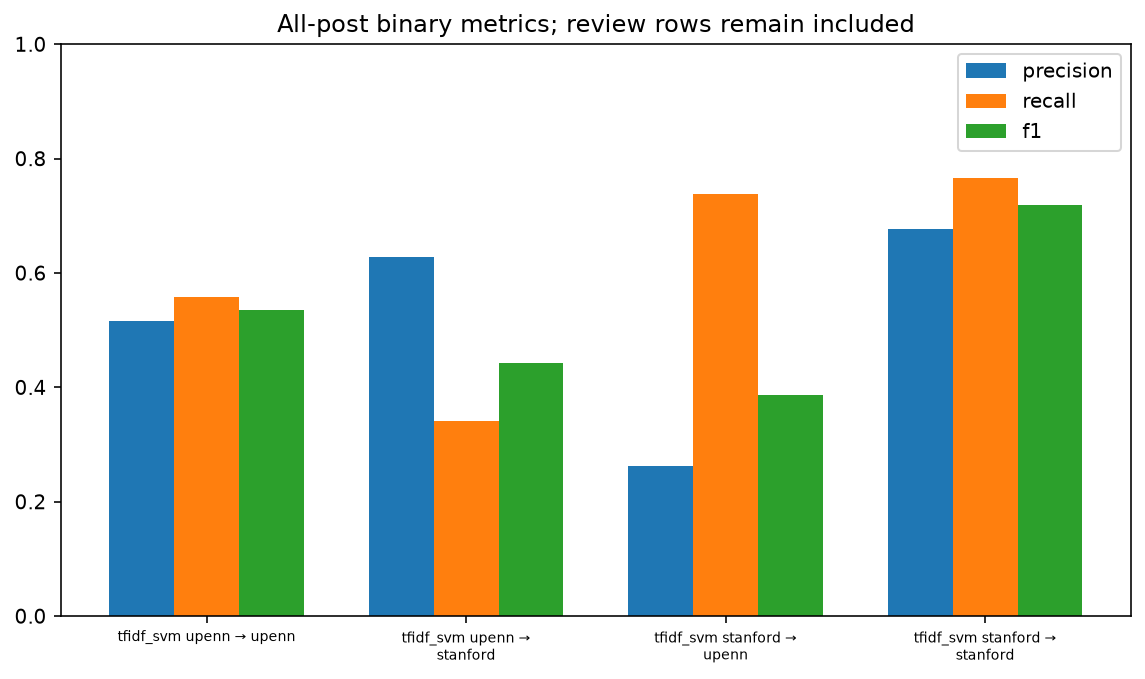

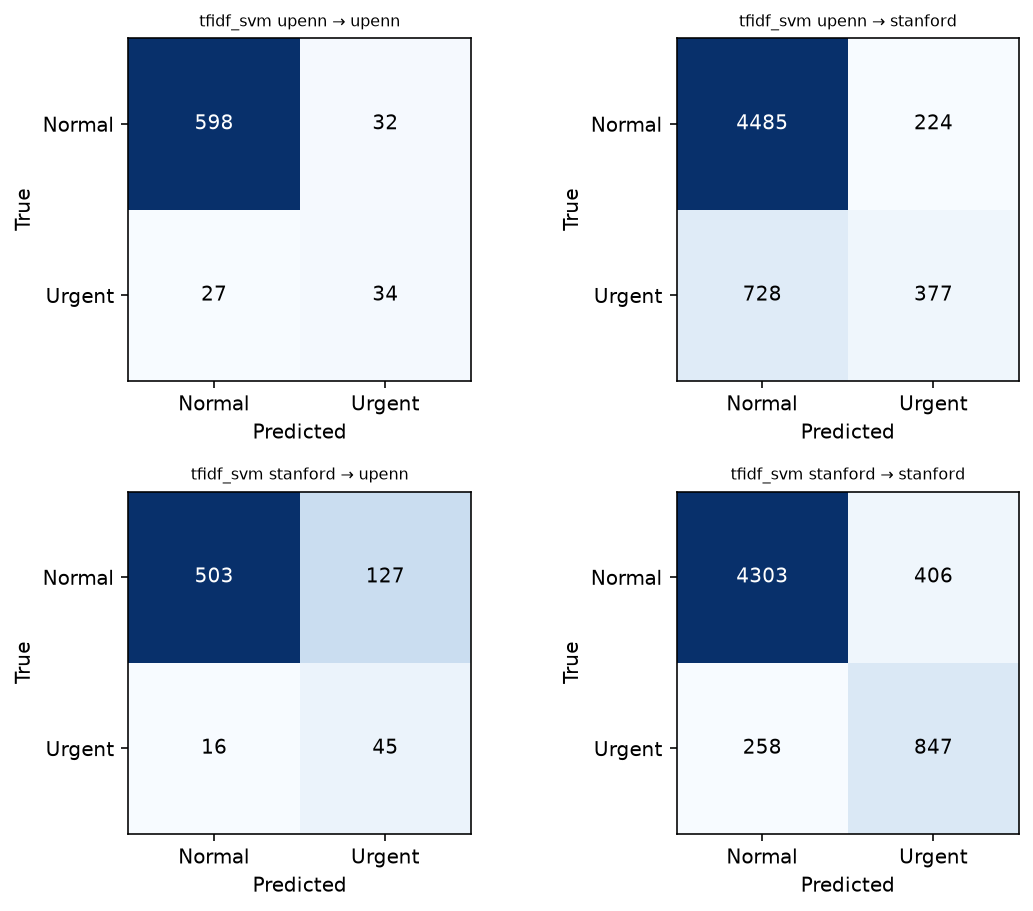

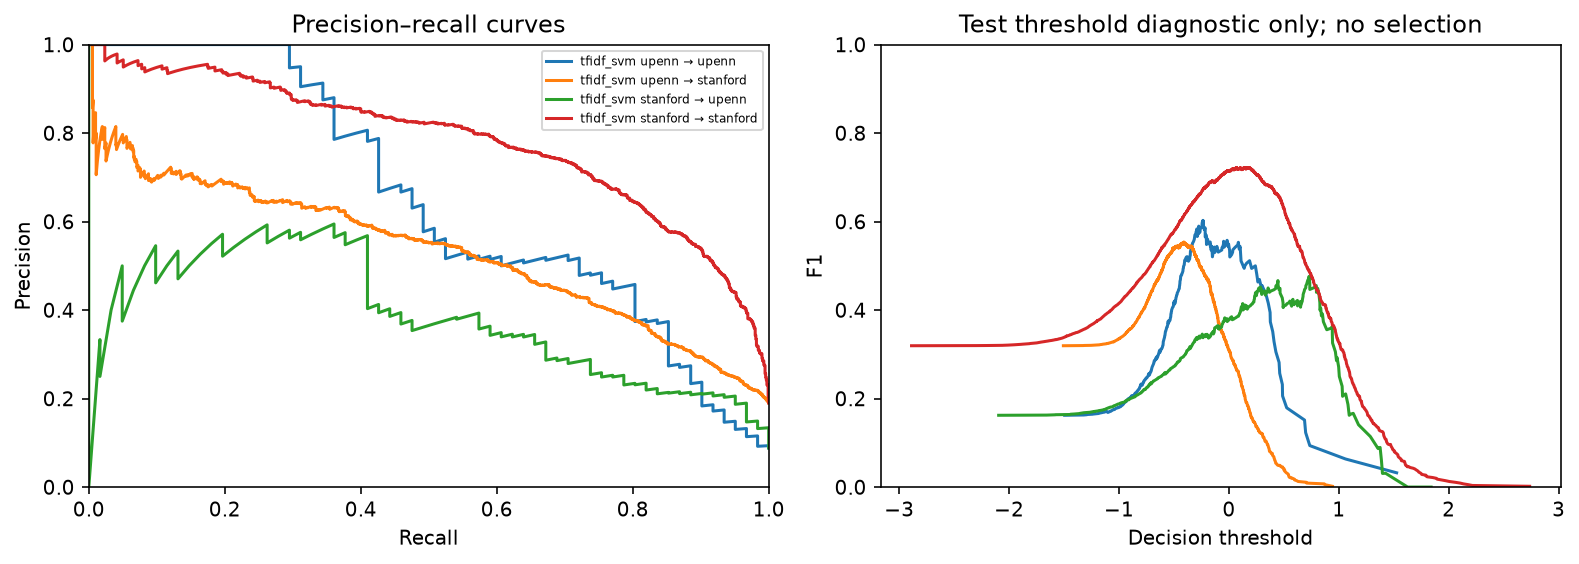

Checks: [
  {
    "experiment": "tfidf_svm upenn \u2192 upenn",
    "count_metrics_match": true,
    "per_post_predictions_checked": true
  },
  {
    "experiment": "tfidf_svm upenn \u2192 stanford",
    "count_metrics_match": true,
    "per_post_predictions_checked": true
  },
  {
    "experiment": "tfidf_svm stanford \u2192 upenn",
    "count_metrics_match": true,
    "per_post_predictions_checked": true
  },
  {
    "experiment": "tfidf_svm stanford \u2192 stanford",
    "count_metrics_match": true,
    "per_post_predictions_checked": true
  }
]
Actual error examples: [
  {
    "experiment": "tfidf_svm upenn \u2192 upenn",
    "all_error_count": 59,
    "examples": [
      {
        "post_id": "upenn_003275",
        "true": 1,
        "predicted": 0,
        "score": -1.1124360776475237,
        "threshold": -0.1646198683014054,
        "error": "FN",
        "text": "What the hell? I posted this thread simply to inform the staff of a small error, that occurred during Dr. [REDACTED

In [16]:
run('teacher_notebook_tools.py','emit','--profile',PROFILE,'--models',*MODEL_KEYS)
rows=read_json('reports/teacher/results.json')
if rows:
    headers=['Method/run','Train → test','Policy','P','R','F1','Accuracy','FP','FN']
    table='| '+' | '.join(headers)+' |\n|'+ '|'.join(['---']*len(headers))+'|\n'
    for r in rows:
        table+='| '+' | '.join([str(r.get('run',r.get('trial_label',r.get('model','method')))),str(r.get('train_source','joint'))+' → '+r['test_source'],str(r.get('policy','')),
            *[f"{r[k]:.4f}" for k in ['precision','recall','f1','accuracy']],str(r['confusion_matrix'][0][1]),str(r['confusion_matrix'][1][0])])+' |\n'
    display(Markdown(table))
    for r in rows:print(json.dumps(r,indent=2))
for relative in read_json('reports/teacher/figure_files.json'):display(Image(filename=str(PROJECT/relative)))
print('Checks:',json.dumps(read_json('reports/teacher/checks.json'),indent=2))
print('Actual error examples:',json.dumps(read_json('reports/teacher/error_examples.json'),indent=2))


## Predict a new English post

Change TEXT_TO_PREDICT and rerun this cell after training is complete. Scores are model estimates; a high score can still be wrong. Review and outside-scope handling are not independently validated semantic classes. Source models use their source-specific saved thresholds.


In [17]:
TEXT_TO_PREDICT='I cannot submit my assignment and the deadline is tonight. Please help!'
MODEL_SOURCE='stanford'
MODEL_KEY=MODEL_KEYS[0]
run('teacher_predict_baseline.py','--model',PROJECT/'models'/f'{MODEL_SOURCE}__{MODEL_KEY}.joblib','--text',TEXT_TO_PREDICT)


{
  "text": "I cannot submit my assignment and the deadline is tonight. Please help!",
  "model": "tfidf_svm",
  "source": "stanford",
  "score": 1.0434491163148163,
  "score_type": "decision_margin",
  "threshold": 0.08191062228048629,
  "binary_priority": 1,
  "note": "English student forum posts; a model estimate can be wrong."
}


## Download the complete experiment output

The ZIP includes source code, dataset provenance/splits, statistics, figures, predictions, and trained model folders when training occurred. Caches and temporary checkpoints are excluded. Explicit local validation omits linked model weights from its QA ZIP; a fresh Kaggle training run includes its actual trained weights. Download the displayed ZIP from Kaggle Output. This notebook does not launch the local web application.


In [18]:
from zipfile import ZipFile,ZIP_DEFLATED
archive=PROJECT/(SLUG+'_output.zip')
with ZipFile(archive,'w',ZIP_DEFLATED) as z:
    for directory in ['scripts','Datasets','reports','models']:
        for path in (PROJECT/directory).rglob('*'):
            if not path.is_file() or path.name=='best_state.pt':continue
            if VALIDATION_REUSE and path.suffix in ['.safetensors','.bin','.pt']:continue
            z.write(path,str(path.relative_to(PROJECT)))
print('Download from Kaggle Output:',archive,'MB:',round(archive.stat().st_size/1e6,1))


Download from Kaggle Output: /Users/nhaterik/lastyear/machine/Project/.cache/teacher-notebooks-validation/02_tfidf_svm/02_tfidf_svm_output.zip MB: 25.6
